# SVM en Google Colab · de los datos a los resultados
### Clasificación de variedades de frijol — Dry Bean

**Exposición de Optimización · Grupo 2**  
Leonardo Panduro · Diego Godoy · Nayara Sernaqué · Jose Cruz

**Pregunta:** ¿podemos reconocer la variedad de un frijol a partir de 16 medidas geométricas?

**Recorrido:** cargar datos → limpiar → separar → escalar → seleccionar SVM → predecir → evaluar.

Este notebook **entrena modelos reales**: las tablas y las gráficas se calculan al ejecutar las celdas. Incluye una copia de resultados de una ejecución verificada para poder leerlo antes de conectarse.

**Cómo usarlo:** en Colab, selecciona **Entorno de ejecución → Ejecutar todas**. Basta una CPU; no necesitas activar GPU ni tener cuenta de Kaggle. La primera ejecución necesita Internet para descargar el Excel público. Las siguientes pueden reutilizar el archivo descargado. El tiempo de búsqueda depende de la máquina; deja terminar antes de exponer.

**Ruta para 10–12 minutos:** secciones 1–12, las gráficas, las animaciones y la conclusión. El apéndice SMO amplía la parte matemática. Abre el índice lateral de Colab para desplazarte por los títulos.

> Alcance: esta es una demostración reproducible sobre un dataset y una partición ya estudiados en el proyecto. La búsqueda didáctica es más pequeña que el protocolo completo E1–E5; sus métricas se generan aquí y no se copian del informe. Repetirla no constituye una nueva validación externa.

Para la expo puedes ir al [ajuste de la frontera y el margen](#scrollTo=svm-guia-frontera) o a la [formación de las nubes de variedades en PCA](#scrollTo=svm-guia-grupos).

## 1. Preparar las herramientas
**Qué hace:** importa las librerías. Si alguna falta, la instala. Registra las versiones para interpretar diferencias entre computadoras.

**Para decir:** “Pandas lee la tabla; scikit-learn entrena la SVM; Matplotlib muestra los resultados”.

In [ ]:
import importlib.util
import subprocess
import sys

# Colab suele incluir estas librerías. Solo instalamos las que faltan.
paquetes = {
    'numpy': 'numpy>=2,<3', 'pandas': 'pandas>=2.2,<4',
    'sklearn': 'scikit-learn>=1.5,<2', 'matplotlib': 'matplotlib>=3.8,<4',
    'openpyxl': 'openpyxl>=3.1,<4', 'joblib': 'joblib>=1.3,<2',
}
faltan = [paquete for modulo, paquete in paquetes.items()
          if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltan])

import hashlib
import json
import platform
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.request import urlopen

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import openpyxl
import sklearn
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Usamos esta semilla para poder repetir la división de filas y los pliegues.
SEMILLA = 42
SALIDA = Path('resultados_svm')
SALIDA.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
# La tabla de versiones documenta el entorno con el que obtuvimos las cifras.
versiones = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'matplotlib': matplotlib.__version__, 'openpyxl': openpyxl.__version__,
            'joblib': joblib.__version__}
display(pd.Series(versiones, name='Versión').to_frame())

,Versión
python,3.14.3
numpy,2.5.0
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.0
openpyxl,3.1.5
joblib,1.6.0


## 2. Cargar el dataset, como en Kaggle
**Qué hace:** descarga el Excel del repositorio y lo carga con `pd.read_excel`. Comprueba su huella SHA-256 para usar exactamente los datos del proyecto.

También puedes subir `Dry_Bean_Dataset.xlsx` desde el panel **Archivos → Subir** y cambiar `MODO_CARGA` a `manual`. Para otro dataset haría falta adaptar las columnas y el protocolo: este notebook valida Dry Bean.

**Datos:** 13 611 observaciones, 16 medidas y 7 clases. Son medidas extraídas de imágenes; este archivo no contiene fotografías. Fuente: [UCI Dry Bean](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset), DOI [10.24432/C50S4B](https://doi.org/10.24432/C50S4B).

**Para decir:** “Cada fila representa un frijol. Las primeras 16 columnas son sus medidas y `Class` es la respuesta conocida”.

In [ ]:
MODO_CARGA = 'automatico' # @param ['automatico', 'manual']
# Fijamos una revisión del repositorio para que todos descarguemos el mismo Excel.
COMMIT_FUENTE = '99538c63f317ddafdc072b991045b8821d0dc0fb'
SHA256_ESPERADO = 'a9efa69741c6c5d95167c962a13da23a456f7e940402a5add12639790e01f714'
URL_DATOS = (f'https://raw.githubusercontent.com/leonardopanduro-rgb/'
             f'optimizacion-/{COMMIT_FUENTE}/data/Dry_Bean_Dataset.xlsx')
RUTA_DATOS = Path('Dry_Bean_Dataset.xlsx')

# Reutilizamos el archivo de la sesión cuando ya está en el panel Archivos.
if not RUTA_DATOS.exists():
    if MODO_CARGA == 'manual':
        raise FileNotFoundError('Sube Dry_Bean_Dataset.xlsx al panel Archivos y repite esta celda.')
    with urlopen(URL_DATOS, timeout=60) as respuesta:
        contenido = respuesta.read()
    if hashlib.sha256(contenido).hexdigest() != SHA256_ESPERADO:
        raise ValueError('La descarga no coincide con el dataset verificado.')
    RUTA_DATOS.write_bytes(contenido)

# Comparamos la huella del Excel con la del original, también si se subió a mano.
hash_datos = hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest()
if hash_datos != SHA256_ESPERADO:
    raise ValueError('El archivo local no es la copia de Dry Bean usada en el proyecto.')

# Leemos una fila por frijol. head() permite reconocer las medidas y la etiqueta Class.
datos_originales = pd.read_excel(RUTA_DATOS)
print(f'Excel cargado: {datos_originales.shape[0]:,} filas × {datos_originales.shape[1]} columnas')
display(datos_originales.head())

Excel cargado: 13,611 filas × 17 columnas


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Revisar y limpiar antes de dividir
**Qué hace:** cuenta faltantes y duplicados; elimina únicamente filas exactas repetidas. Se hace antes de separar para evitar que una copia quede en entrenamiento y otra en prueba.

**Para decir:** “Un registro repetido no debe aparecer a ambos lados del examen. Aquí no hace falta imputar datos porque no hay valores faltantes”.

In [ ]:
# Contamos primero lo que encontramos en el Excel original para poder explicarlo.
faltantes = int(datos_originales.isna().sum().sum())
duplicados = int(datos_originales.duplicated().sum())
# Quitamos las copias exactas antes de dividir para que una copia no llegue al test.
datos = datos_originales.drop_duplicates().reset_index(drop=True)

# Estas comprobaciones confirman que analizamos la versión de Dry Bean del proyecto.
assert datos_originales.shape == (13611, 17), 'Revisar estructura del Excel.'
assert faltantes == 0, 'Hay faltantes: revisar el protocolo antes de continuar.'
assert duplicados == 68 and len(datos) == 13543
assert datos['Class'].nunique() == 7

resumen_datos = pd.DataFrame({
    'Concepto': ['Filas originales', 'Duplicados eliminados', 'Filas para analizar',
                 'Valores faltantes', 'Variables de entrada', 'Clases'],
    'Cantidad': [len(datos_originales), duplicados, len(datos), faltantes, 16, 7],
})
display(resumen_datos)
resumen_datos.to_csv(SALIDA / 'resumen_datos.csv', index=False)

,Concepto,Cantidad
0,Filas originales,13611
1,Duplicados eliminados,68
2,Filas para analizar,13543
3,Valores faltantes,0
4,Variables de entrada,16
5,Clases,7


## 4. Entender las entradas X y la respuesta y
`X` contiene las medidas numéricas: área, perímetro, longitudes y descriptores de forma. `y` contiene la etiqueta `Class`.

Por ejemplo, `Area` mide el área en píxeles; `AspectRation` es el nombre que usa este Excel para la relación entre el eje mayor y el menor. Conservamos los nombres originales para predecir con el mismo orden de columnas.

**Para decir:** “X es lo que le entregamos al modelo; y es lo que queremos que aprenda a identificar”.

,Variable,Tipo
0,Area,int64
1,Perimeter,float64
2,MajorAxisLength,float64
3,MinorAxisLength,float64
4,AspectRation,float64
5,Eccentricity,float64
6,ConvexArea,int64
7,EquivDiameter,float64
8,Extent,float64
9,Solidity,float64


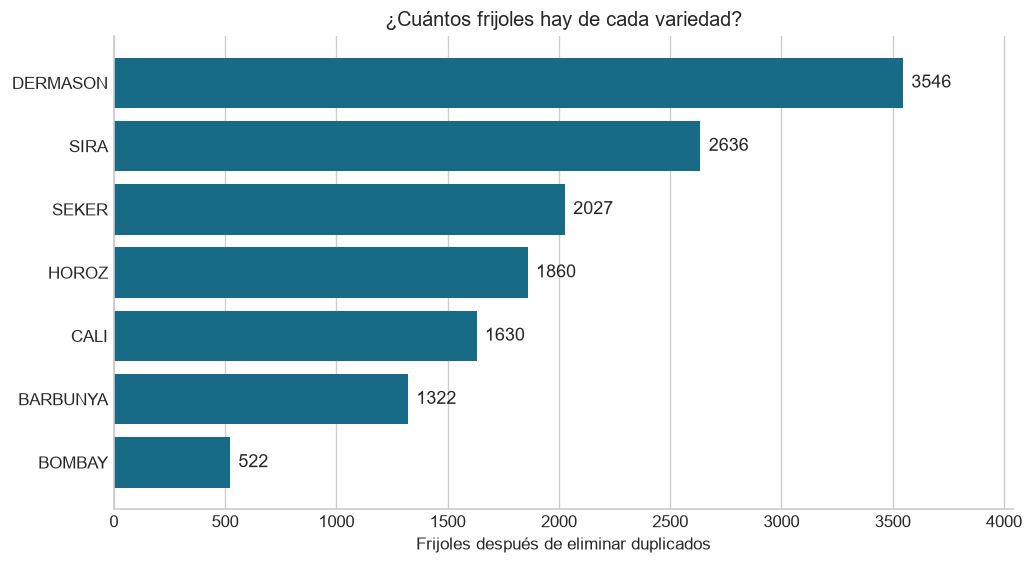

Cada clase pesa lo mismo en F1 macro, aunque tenga menos ejemplos.


In [ ]:
# X conserva las 16 medidas disponibles cuando llega un frijol nuevo.
# Class contiene la respuesta. Las 16 columnas restantes describen el frijol.
X = datos.drop(columns='Class')
# y contiene la respuesta conocida que enseñamos al modelo durante el entrenamiento.
y = datos['Class']
assert X.shape[1] == 16 and all(pd.api.types.is_numeric_dtype(X[c]) for c in X)
CLASES = sorted(y.unique())
display(pd.DataFrame({'Variable': X.columns, 'Tipo': X.dtypes.astype(str).values}))

# Ordenar las barras por frecuencia permite comparar el tamaño de las clases.
conteos = y.value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.6), layout='constrained')
barras = ax.barh(conteos.index, conteos, color='#176B87')
ax.bar_label(barras, padding=5, fontsize=11)
ax.set_xlim(0, conteos.max() * 1.14)
ax.set(title='¿Cuántos frijoles hay de cada variedad?', xlabel='Frijoles después de eliminar duplicados')
ax.grid(False, axis='y')
ax.set_axisbelow(True)
fig.savefig(SALIDA / '01_clases.png', dpi=170, bbox_inches='tight')
plt.show()
print('Cada clase pesa lo mismo en F1 macro, aunque tenga menos ejemplos.')

## 5. Separar entrenamiento y prueba
**Qué hace:** con la configuración inicial reserva 20 % para evaluar al final y usa 80 % para entrenar y seleccionar parámetros. `stratify=y` conserva aproximadamente las proporciones de las siete clases. `random_state=42` fija la partición.

La validación cruzada se realizará **dentro del conjunto de entrenamiento**. El test no participa en el escalado ni en la búsqueda de parámetros.

**Para decir:** “El entrenamiento es la práctica; la validación ayuda a elegir la configuración; el test es el examen final”.

In [ ]:
FRACCION_PRUEBA = 0.20
# test_size reserva la fracción de prueba. stratify conserva aproximadamente la proporción de cada variedad.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=FRACCION_PRUEBA, random_state=SEMILLA, stratify=y
)
# Comprobamos que cada fila limpia pertenezca a una sola partición.
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(datos)

# Comparamos los conteos por variedad para ver cómo quedó el reparto.
particion = pd.DataFrame({'Entrenamiento': y_train.value_counts(),
                          'Prueba': y_test.value_counts()}).sort_index()
display(particion)
print(f'Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}')
particion.to_csv(SALIDA / 'particion_por_clase.csv')
pd.DataFrame({'fila_limpia': datos.index,
              'particion': np.where(datos.index.isin(X_train.index), 'train', 'test')}
             ).to_csv(SALIDA / 'indices_particion.csv', index=False)

,Entrenamiento,Prueba
Class,,
BARBUNYA,1057,265
BOMBAY,418,104
CALI,1304,326
DERMASON,2837,709
HOROZ,1488,372
SEKER,1621,406
SIRA,2109,527


Entrenamiento: 10,834 | Prueba: 2,709


## 6. Construir el modelo SVM: el código central
**Qué hace:** encadena un escalador con una SVM de clasificación (`SVC`).

| Código | Explicación para la exposición |
|---|---|
| `StandardScaler()` | Centra cada variable y la divide por su desviación; impide que la magnitud de las unidades domine las distancias. |
| `Pipeline(...)` | Mantiene unidos el escalado y el modelo. En CV, aprende el escalador solo con el entrenamiento de cada pliegue. |
| `kernel='rbf'` | Permite fronteras curvas basadas en similitud entre puntos. |
| `C` | Penaliza las violaciones del margen; valores grandes penalizan más. |
| `gamma` | Controla qué tan local es la influencia de cada punto en RBF. |
| `fit(X_train, y_train)` | Aprende los parámetros del modelo. |
| `predict(X_test)` | Aplica el modelo aprendido a otras observaciones. |

`SVC` resuelve las siete clases internamente con **uno contra uno (OvO): 21 problemas binarios**. Cambiar `decision_function_shape` a `'ovr'` solo cambia la presentación de los scores; no cambia ese entrenamiento.

**Para decir:** “La SVM busca separar las clases con un margen amplio, permitiendo errores controlados por C”.

In [ ]:
# Esta es la plantilla. La siguiente sección elegirá C, gamma y el kernel con CV.
pipeline = Pipeline([
    # Cada pliegue aprende la media y la desviación con sus propias filas de entrenamiento.
    ('escalador', StandardScaler()),
    # SVC recibe las medidas escaladas. RBF mide la similitud entre pares de frijoles.
    ('svm', SVC(kernel='rbf', cache_size=256)),
])
print(pipeline)

Pipeline(steps=[('escalador', StandardScaler()), ('svm', SVC(cache_size=256))])


## 7. Seleccionar la configuración con validación cruzada
Con los valores iniciales compara 12 configuraciones: tres SVM lineales y nueve RBF. Cada una usa cinco pliegues estratificados: **60 entrenamientos de validación** y después un ajuste final con todo el entrenamiento.

Seleccionamos por **F1 macro**: calcula F1 para cada clase y promedia dando el mismo peso a cada una. `GridSearchCV` no recibe el test.

Esta malla acotada facilita una demo. No es la búsqueda completa de dos etapas de E1–E5 y no garantiza el mejor parámetro entre todos los valores posibles. El mejor promedio CV se usa para seleccionar, no como una estimación imparcial definitiva.

**Para decir:** “Comparamos configuraciones con las mismas particiones y elegimos la que mejor equilibra las siete clases”.

In [ ]:
# En cada ronda un pliegue valida la configuración y los restantes sirven para entrenarla.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
# C penaliza violaciones del margen. En RBF, subir gamma concentra la influencia de cada punto.
MODO_KERNEL = 'ambos' # @param ['ambos', 'solo lineal', 'solo RBF']
malla = [
    {'svm__kernel': ['linear'], 'svm__C': [1, 8, 64]},
    {'svm__kernel': ['rbf'], 'svm__C': [1, 8, 64],
     'svm__gamma': [1/128, 1/64, 1/32]},
]
# Para el ensayo, decide qué kernels participan antes de entrenar.
if MODO_KERNEL == 'solo lineal':
    malla = [grupo for grupo in malla if grupo['svm__kernel'] == ['linear']]
elif MODO_KERNEL == 'solo RBF':
    malla = [grupo for grupo in malla if grupo['svm__kernel'] == ['rbf']]
print(f'{len(list(ParameterGrid(malla)))} configuraciones × {cv.n_splits} pliegues.')
# Cada configuración compite por su F1 macro medio. Cada una de las siete variedades pesa igual.
busqueda = GridSearchCV(
    pipeline, malla, scoring='f1_macro', cv=cv,
    n_jobs=2, pre_dispatch=2, refit=True, return_train_score=False, error_score='raise'
)
inicio = time.perf_counter()
busqueda.fit(X_train, y_train)  # aquí se entrena; no se leen resultados guardados
segundos_busqueda = time.perf_counter() - inicio
modelo = busqueda.best_estimator_  # ya reajustado con todo X_train
print('Mejores parámetros:', busqueda.best_params_)
print(f'Mejor F1 macro CV: {busqueda.best_score_:.4f}')
print(f'Tiempo local de búsqueda y reajuste: {segundos_busqueda:.1f} s')

# mean_test_score es aquí el promedio de validación interna. X_test sigue reservado para el examen final.
tabla_cv = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_score')
tabla_cv.to_csv(SALIDA / 'validacion_cruzada.csv', index=False)
columnas_cv = ['param_svm__kernel', 'param_svm__C', 'param_svm__gamma',
               'mean_test_score', 'std_test_score', 'rank_test_score']
# Gamma se define para RBF. Si solo probamos modelos lineales, se omite esa columna.
display(tabla_cv.filter(items=columnas_cv).reset_index(drop=True))

12 configuraciones × 5 pliegues.


Mejores parámetros: {'svm__C': 64, 'svm__gamma': 0.015625, 'svm__kernel': 'rbf'}
Mejor F1 macro CV: 0.9448
Tiempo local de búsqueda y reajuste: 69.1 s


,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,64,0.015625,0.944807,0.005437,1
1,rbf,64,0.031250,0.944084,0.005651,2
2,rbf,8,0.031250,0.943239,0.005394,3
3,rbf,64,0.007812,0.942451,0.006127,4
4,rbf,8,0.015625,0.941720,0.005624,5
5,rbf,8,0.007812,0.940726,0.005191,6
6,rbf,1,0.031250,0.940017,0.005849,7
7,linear,64,NaN,0.939147,0.004772,8
8,linear,8,NaN,0.938955,0.004982,9
9,linear,1,NaN,0.938878,0.004509,10


## 8. Visualizar el efecto de C y gamma
**Qué hace:** muestra el F1 macro de validación para cada combinación RBF. Si eliges solo el kernel lineal, muestra el F1 según C. Los valores vienen de la búsqueda anterior.

**Para decir:** “No elegimos por una gráfica del test. Este mapa muestra el efecto de los parámetros usando solo validación dentro del entrenamiento”.

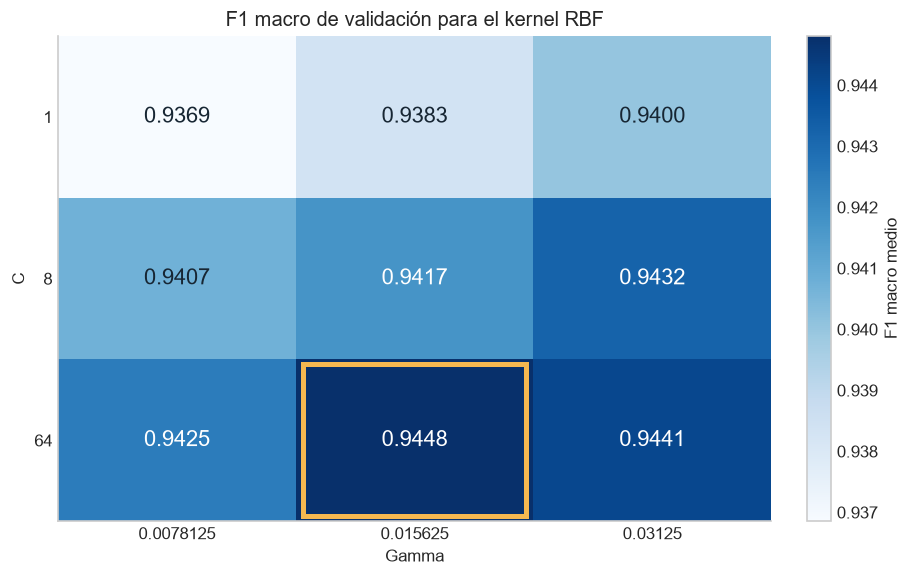

Mejor configuración RBF del mapa: C=64, gamma=0.015625, F1 macro=0.9448.


In [ ]:
from matplotlib.patches import Rectangle

# Cada casilla contiene el F1 macro medio de los cinco pliegues de entrenamiento.
rbf_cv = tabla_cv.loc[tabla_cv['param_svm__kernel'] == 'rbf'].copy()
if rbf_cv.empty:
    # Si en la sección 7 solo probaste kernels lineales, muestra su F1 según C.
    lineales = tabla_cv.loc[tabla_cv['param_svm__kernel'] == 'linear'].sort_values('param_svm__C')
    fig, ax = plt.subplots(figsize=(7.5, 4.3), layout='constrained')
    ax.plot(range(len(lineales)), lineales['mean_test_score'], 'o-', color='#176B87')
    ax.set_xticks(range(len(lineales)), [f'{float(c):g}' for c in lineales['param_svm__C']])
    ax.set(xlabel='C', ylabel='F1 macro medio', title='Validación cruzada del kernel lineal')
    ax.margins(y=0.35)
    fig.savefig(SALIDA / '02_mapa_cv.png', dpi=170, bbox_inches='tight')
    plt.show()
else:
    mapa = rbf_cv.pivot(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score')
    valores = mapa.to_numpy(dtype=float)
    fila_mejor, columna_mejor = np.unravel_index(valores.argmax(), valores.shape)

    fig, ax = plt.subplots(figsize=(7.5, 4.7), layout='constrained')
    im = ax.imshow(valores, cmap='Blues', aspect='auto')
    ax.grid(False)  # Mantiene los números legibles sobre las celdas.
    ax.set_xticks(range(len(mapa.columns)), [f'{float(g):g}' for g in mapa.columns])
    ax.set_yticks(range(len(mapa.index)), [str(c) for c in mapa.index])
    ax.set(xlabel='Gamma', ylabel='C', title='F1 macro de validación para el kernel RBF')
    for fila, columna in np.ndindex(valores.shape):
        valor = valores[fila, columna]
        color_texto = 'white' if im.norm(valor) > 0.55 else '#172633'
        ax.text(columna, fila, f'{valor:.4f}', ha='center', va='center', color=color_texto, fontsize=13)
    # El marco marca el máximo dentro de la malla RBF.
    ax.add_patch(Rectangle((columna_mejor-0.47, fila_mejor-0.47), 0.94, 0.94,
                           fill=False, edgecolor='#F6B850', linewidth=3))
    fig.colorbar(im, ax=ax, label='F1 macro medio')
    fig.savefig(SALIDA / '02_mapa_cv.png', dpi=170, bbox_inches='tight')
    plt.show()
    print(f'Mejor configuración RBF del mapa: C={mapa.index[fila_mejor]}, '
          f'gamma={float(mapa.columns[columna_mejor]):g}, F1 macro={valores.max():.4f}.')

## 9. Predecir y medir los resultados finales
**Qué hace:** aplica una vez el modelo seleccionado al test y calcula accuracy y F1 macro. Añadimos una referencia simple que siempre responde la clase mayoritaria.

**Accuracy:** proporción total de aciertos. **Precisión por clase:** cuántas predicciones de esa clase fueron correctas. **Recall:** cuántos ejemplos reales de esa clase detectó. **F1:** media armónica de precisión y recall. **Support:** cantidad de ejemplos de cada clase en el test.

**Para decir:** “Reportamos resultados sobre las filas de prueba que no participaron en esta búsqueda. Accuracy cuenta aciertos globales; F1 macro da el mismo peso a cada variedad”.

No uses estos resultados para volver a ajustar C, gamma o la malla y seguir llamando independiente al mismo test.

In [ ]:
# El pipeline aplica el escalado aprendido y asigna una variedad a cada frijol de prueba.
y_pred = modelo.predict(X_test)
# La referencia siempre elige la variedad más frecuente del entrenamiento.
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_base = baseline.predict(X_test)
# Accuracy cuenta aciertos sobre todos los frijoles. F1 macro promedia los F1 de las siete variedades.
metricas = pd.DataFrame([
    {'Modelo': 'Clase mayoritaria', 'Accuracy': accuracy_score(y_test, pred_base),
     'F1 macro': f1_score(y_test, pred_base, average='macro', zero_division=0)},
    {'Modelo': 'SVM seleccionada por CV', 'Accuracy': accuracy_score(y_test, y_pred),
     'F1 macro': f1_score(y_test, y_pred, average='macro', zero_division=0)},
])
display(metricas.style.format({'Accuracy': '{:.4f}', 'F1 macro': '{:.4f}'}))
# El reporte desglosa los resultados para identificar las variedades más difíciles.
reporte = pd.DataFrame(classification_report(
    y_test, y_pred, labels=CLASES, output_dict=True, zero_division=0
)).T.drop(index='accuracy')  # La exactitud global ya aparece en la primera tabla.
reporte['support'] = reporte['support'].astype(int)
display(reporte.rename(columns={'precision': 'Precisión', 'recall': 'Sensibilidad',
                               'f1-score': 'F1', 'support': 'Frijoles de prueba'}).round(4))
metricas.to_csv(SALIDA / 'metricas_test.csv', index=False)
reporte.to_csv(SALIDA / 'reporte_clasificacion.csv')
predicciones = pd.DataFrame({'fila_limpia': X_test.index,
                            'clase_real': y_test.to_numpy(), 'clase_predicha': y_pred})
predicciones['acierto'] = predicciones['clase_real'] == predicciones['clase_predicha']
predicciones.to_csv(SALIDA / 'predicciones_test.csv', index=False)

,Modelo,Accuracy,F1 macro
0,Clase mayoritaria,0.2617,0.0593
1,SVM seleccionada por CV,0.9232,0.9343


,Precisión,Sensibilidad,F1,Frijoles de prueba
BARBUNYA,0.9202,0.9132,0.9167,265
BOMBAY,1.0000,1.0000,1.0000,104
CALI,0.9242,0.9356,0.9299,326
DERMASON,0.9171,0.9210,0.9191,709
HOROZ,0.9668,0.9382,0.9523,372
SEKER,0.9463,0.9557,0.9510,406
SIRA,0.8696,0.8729,0.8712,527
macro avg,0.9349,0.9338,0.9343,2709
weighted avg,0.9234,0.9232,0.9233,2709


## 10. Explicar los errores con la matriz de confusión
**Cómo leerla:** las filas son las clases reales y las columnas, las predichas. La diagonal representa aciertos. Cada fila de la matriz de la derecha suma aproximadamente 100 %; sirve para comparar clases de distintos tamaños.

**Para decir:** “No basta con un porcentaje total: esta matriz muestra exactamente entre qué variedades se confunde el modelo”.

Marco naranja: 49 de los 527 frijoles SIRA fueron clasificados como DERMASON.


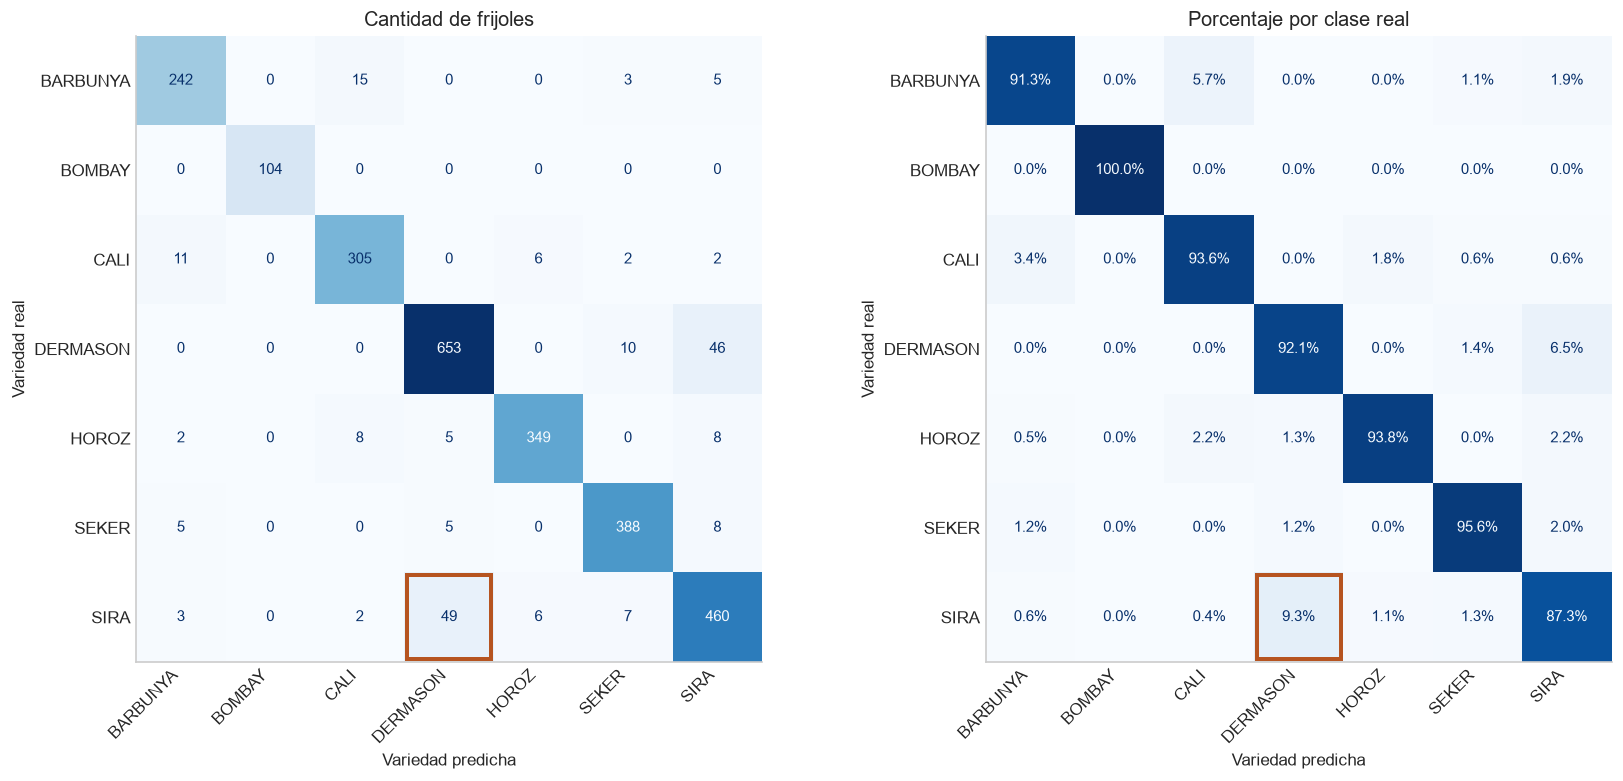

In [ ]:
# Las filas son clases reales y las columnas, predicciones sobre los mismos frijoles.
fig, ejes = plt.subplots(1, 2, figsize=(14.1, 6.4), layout='constrained')
cm = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=CLASES, cmap='Blues', ax=ejes[0],
    colorbar=False, xticks_rotation=45, values_format='d'
)
# normalize='true' divide cada fila entre el total REAL de esa variedad.
relativo = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=CLASES, normalize='true', cmap='Blues', ax=ejes[1],
    colorbar=False, xticks_rotation=45, values_format='.1%'
)
for panel, titulo in zip([cm, relativo], ['Cantidad de frijoles', 'Porcentaje por clase real']):
    panel.ax_.set(title=titulo, xlabel='Variedad predicha', ylabel='Variedad real')
    panel.ax_.grid(False)
    for texto in panel.text_.flat:
        texto.set_fontsize(9)
    for etiqueta in panel.ax_.get_xticklabels():
        etiqueta.set_ha('right')
# Buscar el error más frecuente: excluir primero la diagonal de aciertos.
sin_diagonal = cm.confusion_matrix.copy()
np.fill_diagonal(sin_diagonal, 0)
i, j = np.unravel_index(sin_diagonal.argmax(), sin_diagonal.shape)
if sin_diagonal[i, j] > 0:
    from matplotlib.patches import Rectangle
    for ax in ejes:
        ax.add_patch(Rectangle((j-0.47, i-0.47), 0.94, 0.94, fill=False,
                               edgecolor='#B65420', linewidth=2.4))
    print(f'Marco naranja: {sin_diagonal[i, j]} de los {cm.confusion_matrix[i].sum()} '
          f'frijoles {CLASES[i]} fueron clasificados como {CLASES[j]}.')
fig.savefig(SALIDA / '03_matriz_confusion.png', dpi=180, bbox_inches='tight')
plt.show()
pd.DataFrame(cm.confusion_matrix, index=CLASES, columns=CLASES).to_csv(SALIDA / 'matriz_confusion.csv')

## 11. Demostración: clasificar un frijol
**Qué hace:** toma una observación del test ya evaluado, muestra sus 16 medidas y revela la clase real después de predecir. Es una demostración de inferencia, no un nuevo experimento ni un nuevo dato externo.

Cambia `FILA_DEMO` y ejecuta esta celda para probar otra fila. No hace falta volver a entrenar.

**Para decir:** “Para predecir entrego las medidas sin incluir Class. El modelo aplica el mismo escalado aprendido y devuelve una variedad”.

In [ ]:
FILA_DEMO = 0 # @param {type:'integer'}
# Para la demo, cambia FILA_DEMO y ejecuta de nuevo solo esta celda.
if not 0 <= FILA_DEMO < len(X_test):
    raise ValueError(f'Usa un número entre 0 y {len(X_test)-1}.')
frijol = X_test.iloc[[FILA_DEMO]]  # doble corchete: mantener formato de tabla
# La predicción usa las 16 medidas y el escalador que ya aprendió el pipeline.
clase_estimada = modelo.predict(frijol)[0]
# Recuperamos la etiqueta después de predecir para comprobar este ejemplo.
clase_real = y_test.iloc[FILA_DEMO]
display(frijol.T.rename(columns={frijol.index[0]: 'Medida del frijol'}))
print('Predicción de la SVM:', clase_estimada)
print('Respuesta conocida: ', clase_real)
print('¿Coinciden?:', clase_estimada == clase_real)

,Medida del frijol
Area,40512.000000
Perimeter,737.636000
MajorAxisLength,248.202030
MinorAxisLength,208.525152
AspectRation,1.190274
Eccentricity,0.542365
ConvexArea,40973.000000
EquivDiameter,227.115566
Extent,0.744268
Solidity,0.988749


Predicción de la SVM: SEKER
Respuesta conocida:  SEKER
¿Coinciden?: True


## 12. ¿Cuáles son los vectores soporte?
**Qué hace:** cuenta las observaciones de entrenamiento que intervienen en la función de decisión de la SVM. No se dibuja una frontera de 16 dimensiones en dos ejes, porque eso podría confundir la representación con el modelo completo.

**Para decir:** “Los vectores soporte son los puntos que sostienen la frontera. En margen suave, algunos pueden estar dentro del margen o incluso estar mal clasificados”.

In [ ]:
# Extraemos el clasificador ya entrenado del último paso del pipeline.
svc = modelo.named_steps['svm']
# n_support_ cuenta por variedad los frijoles que intervienen como soporte en la decisión.
soportes = pd.Series(svc.n_support_, index=svc.classes_, name='Vectores soporte')
display(soportes.to_frame())
print(f'Total: {len(svc.support_):,} / {len(X_train):,} observaciones de entrenamiento '
      f'({len(svc.support_)/len(X_train):.1%}).')
soportes.to_csv(SALIDA / 'vectores_soporte_por_clase.csv')

,Vectores soporte
BARBUNYA,159
BOMBAY,9
CALI,188
DERMASON,498
HOROZ,180
SEKER,173
SIRA,628


Total: 1,835 / 10,834 observaciones de entrenamiento (16.9%).


## Visual 1 · Ver las siete variedades agrupadas
**Cada punto es un frijol; color y símbolo representan su variedad real.** Los colores se asignan a etiquetas conocidas: no estamos ejecutando un algoritmo de clustering.

El dataset tiene 16 medidas. Usamos **PCA** después del escalado para resumirlas en dos ejes. PCA combina medidas para conservar variabilidad de las entradas, sin usar las etiquetas. Tanto el escalador como PCA se ajustan solo con entrenamiento.

Mostramos una muestra fija de **90 frijoles de prueba por variedad** para que los grupos se puedan leer. La muestra balanceada es solo para dibujar; no cambia el entrenamiento ni la evaluación del modelo principal.

**Para decir:** “Aquí vemos qué variedades se parecen según sus medidas. Los grupos alejados se distinguen con más facilidad en esta vista; donde los colores se mezclan, estas dos coordenadas no bastan para separarlos perfectamente”.

El porcentaje de variabilidad explicado por PCA no es el porcentaje de acierto. El solapamiento en este plano tampoco demuestra que dos clases sean inseparables con las 16 medidas.

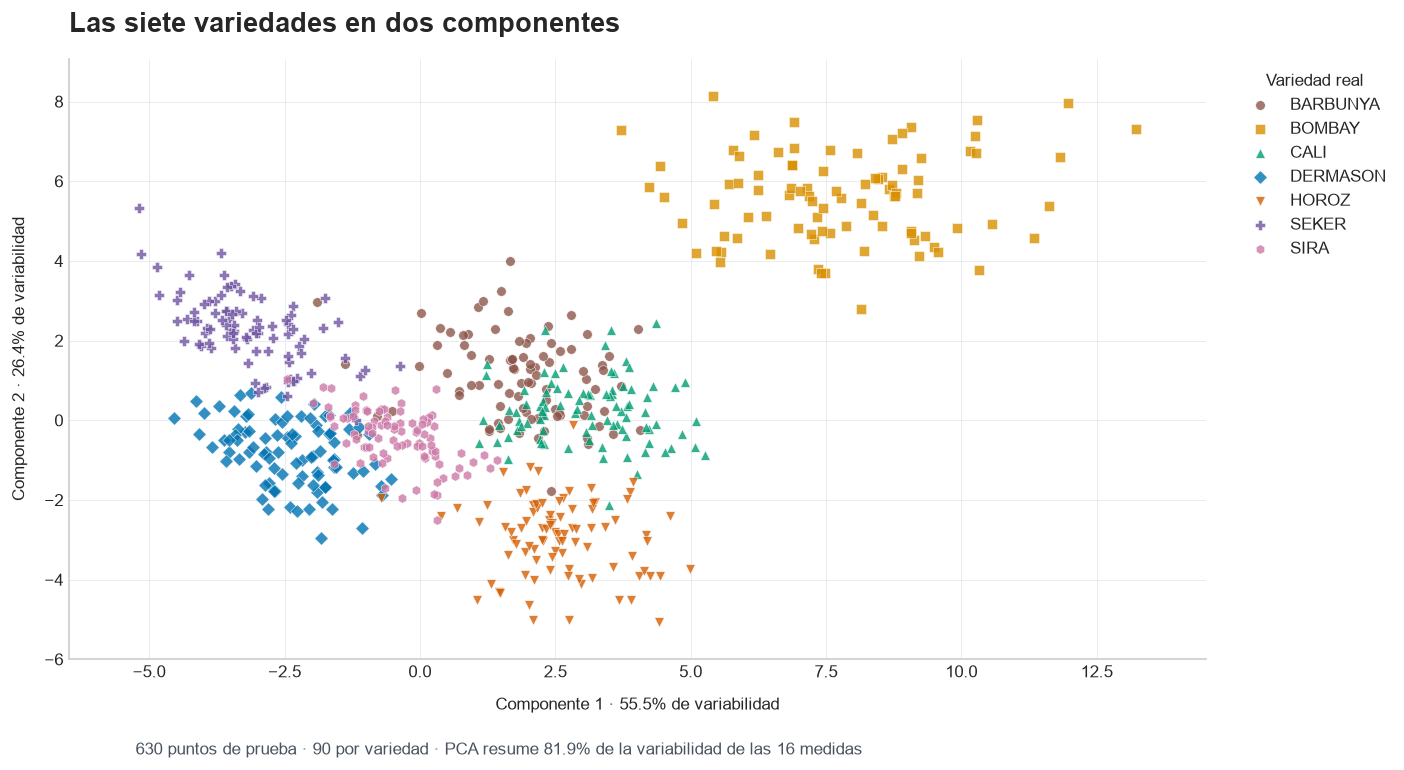

PCA conserva 81.90% de la variabilidad; esto no es accuracy.


In [ ]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Reducir las 16 medidas a dos coordenadas, aprendiendo solo del entrenamiento.
proyeccion = Pipeline([
    ('escalador', StandardScaler()),
    ('pca', PCA(n_components=2, svd_solver='full')),
])
Z_train = proyeccion.fit_transform(X_train)
Z_test = proyeccion.transform(X_test)
varianza_pca = proyeccion.named_steps['pca'].explained_variance_ratio_

# Mismo color y símbolo para la misma variedad en las dos primeras figuras.
colores_bean = ['#8C564B', '#D89000', '#009E73', '#0072B2', '#D55E00', '#6F55A2', '#CC79A7']
marcas_bean = ['o', 's', '^', 'D', 'v', 'P', 'h']  # Reservamos la cruz negra para los errores.
paleta_bean = ListedColormap(colores_bean)
codigo_clase = {clase: i for i, clase in enumerate(CLASES)}
# Dibujamos el mismo número por clase para que también se vea la menos frecuente.
# La evaluación de accuracy utiliza todas las filas de prueba.
por_clase_visual = min(90, int(y_test.value_counts().min()))
rng_visual = np.random.default_rng(SEMILLA)
posiciones_visual = np.concatenate([
    rng_visual.choice(np.flatnonzero(y_test.to_numpy() == clase), size=por_clase_visual, replace=False)
    for clase in CLASES
])
Z_muestra = Z_test[posiciones_visual]
y_muestra = y_test.to_numpy()[posiciones_visual]

# Los dos gráficos comparten los límites. Cada frijol ocupa el mismo lugar en ambos.
minimos = Z_muestra.min(axis=0)
maximos = Z_muestra.max(axis=0)
relleno = (maximos - minimos) * 0.07
limites_visual = (minimos - relleno, maximos + relleno)

def dibujar_frijoles(ax, Z, etiquetas, tamano=33):
    for clase, color, marca in zip(CLASES, colores_bean, marcas_bean):
        mascara = etiquetas == clase
        ax.scatter(Z[mascara, 0], Z[mascara, 1], s=tamano, c=color, marker=marca,
                   alpha=0.80, edgecolors='white', linewidths=0.35, label=clase, zorder=3)

def configurar_plano(ax):
    ax.set_xlim(limites_visual[0][0], limites_visual[1][0])
    ax.set_ylim(limites_visual[0][1], limites_visual[1][1])
    ax.set_xlabel(f'Componente 1 · {varianza_pca[0]:.1%} de variabilidad', labelpad=10)
    ax.set_ylabel(f'Componente 2 · {varianza_pca[1]:.1%} de variabilidad', labelpad=10)
    ax.grid(color='#D8DDE3', linewidth=0.55, alpha=0.6, zorder=0)
    ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(11.8, 6.5))
dibujar_frijoles(ax, Z_muestra, y_muestra)
configurar_plano(ax)
ax.set_title('Las siete variedades en dos componentes', fontsize=16, weight='bold', loc='left', pad=16)
ax.legend(title='Variedad real', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig.text(0.10, 0.025,
         f'{len(y_muestra)} puntos de prueba · {por_clase_visual} por variedad · PCA resume {varianza_pca.sum():.1%} de la variabilidad de las 16 medidas',
         fontsize=10, color='#49535F')
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(SALIDA / '05_variedades_agrupadas.png', dpi=180, bbox_inches='tight')
fig.savefig(SALIDA / '05_variedades_agrupadas.svg', bbox_inches='tight')
plt.show()
print(f'PCA conserva {varianza_pca.sum():.2%} de la variabilidad; esto no es accuracy.')

## Visual 2 · Las fronteras de clasificación de la SVM
**Fondo de color = clase predicha por la SVM para esa región. Punto = clase real.** Un punto de un color sobre un fondo de otra clase representa un error de este modelo didáctico. Las cruces negras resaltan esos errores en la muestra dibujada.

Entrenamos **otra SVM RBF usando solo las dos componentes anteriores** para que su frontera pueda dibujarse honestamente en un plano. Conservamos `C=64` y `gamma=1/64` como valores ilustrativos; no se realiza otra búsqueda de parámetros ni se elige la figura mirando su acierto de prueba.

La SVM principal utiliza las 16 medidas. **Esta figura no representa su frontera exacta** y su métrica se calcula por separado. El fondo muestra decisiones del modelo incluso en zonas sin ejemplos; esas zonas no prueban que existan frijoles con tales características.

**Para decir:** “La SVM divide el espacio en regiones. Cuando llega un frijol nuevo, el modelo determina en qué región cae y le asigna esa variedad. El kernel RBF permite que los límites sean curvos”.

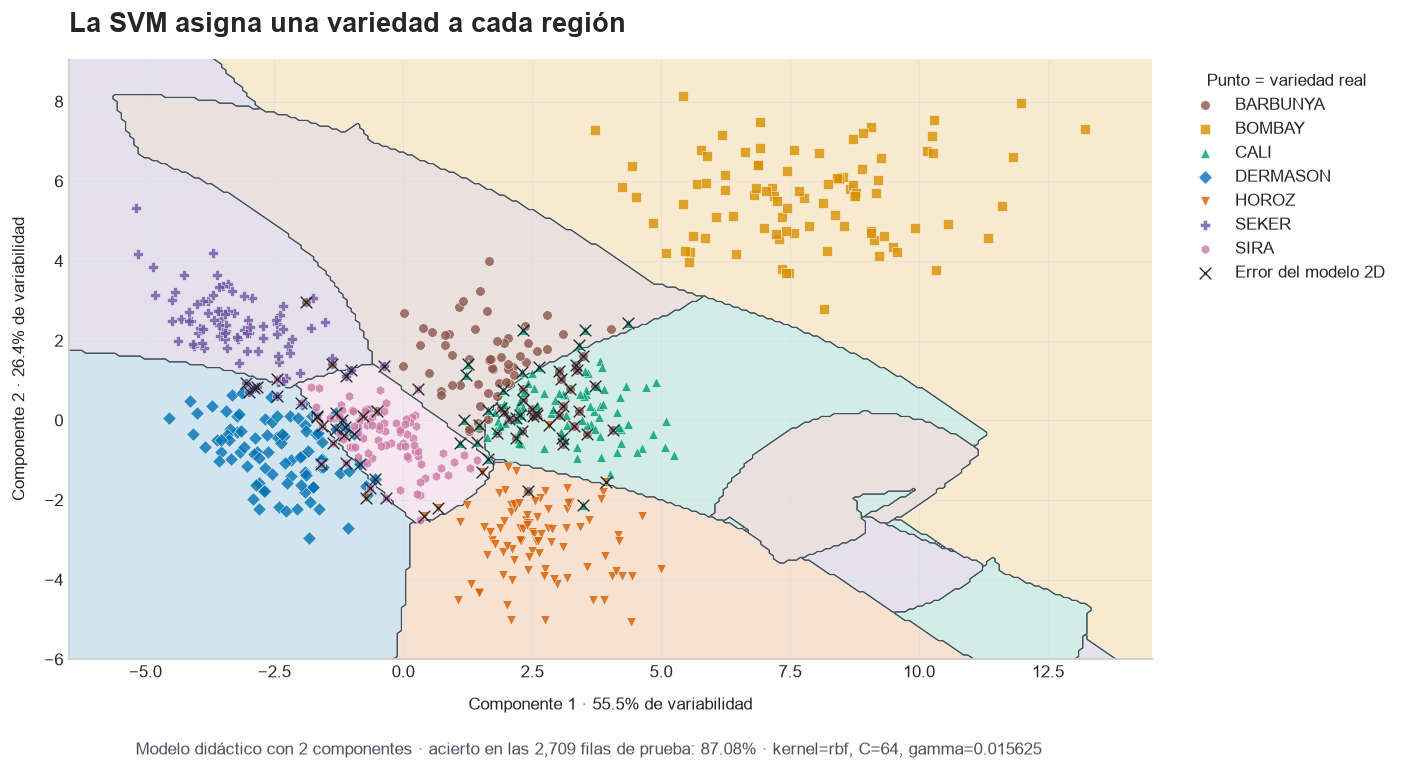

Acierto 2D en todas las filas de prueba: 87.08%. Cruces visibles: 83 de 630 puntos.


In [ ]:
# Modelo didáctico 2D: independiente del modelo principal de 16 medidas.
svm_plano = SVC(kernel='rbf', C=64, gamma=1/64)
svm_plano.fit(Z_train, y_train)
pred_plano_test = svm_plano.predict(Z_test)
accuracy_plano = accuracy_score(y_test, pred_plano_test)

# Preguntar al modelo qué predice en una cuadrícula de coordenadas.
eje_x = np.linspace(limites_visual[0][0], limites_visual[1][0], 260)
eje_y = np.linspace(limites_visual[0][1], limites_visual[1][1], 210)
malla_x, malla_y = np.meshgrid(eje_x, eje_y)
pred_malla = svm_plano.predict(np.column_stack([malla_x.ravel(), malla_y.ravel()]))
regiones = np.array([codigo_clase[c] for c in pred_malla]).reshape(malla_x.shape)
errores_muestra = pred_plano_test[posiciones_visual] != y_muestra

fig, ax = plt.subplots(figsize=(11.8, 6.5))
ax.pcolormesh(malla_x, malla_y, regiones, shading='nearest',
              cmap=paleta_bean, vmin=-0.5, vmax=6.5, alpha=0.18, rasterized=True, zorder=0)
# Una máscara por variedad permite trazar su borde donde cambia de dentro (1) a fuera (0).
# Así, los números que usamos para asignar colores conservan su significado categórico.
for clase in CLASES:
    zona = regiones == codigo_clase[clase]
    if zona.any() and not zona.all():
        ax.contour(malla_x, malla_y, zona.astype(float), levels=[0.5],
                   colors='#42515F', linewidths=0.65, zorder=1)
# Superponer las etiquetas reales permite señalar los errores del ejemplo 2D.
dibujar_frijoles(ax, Z_muestra, y_muestra)
ax.scatter(Z_muestra[errores_muestra, 0], Z_muestra[errores_muestra, 1],
           marker='x', s=49, color='#20262D', linewidths=0.8, zorder=4,
           label='Error del modelo 2D')
configurar_plano(ax)
ax.set_title('La SVM asigna una variedad a cada región', fontsize=16, weight='bold', loc='left', pad=16)
ax.legend(title='Punto = variedad real', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
parametros_plano = f'kernel={svm_plano.kernel}, C={svm_plano.C:g}'
if svm_plano.kernel == 'rbf':
    parametros_plano += f', gamma={svm_plano.gamma}'
fig.text(0.10, 0.025,
         f'Modelo didáctico con 2 componentes · acierto en las {len(X_test):,} filas de prueba: {accuracy_plano:.2%} · {parametros_plano}',
         fontsize=10, color='#49535F')
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(SALIDA / '06_fronteras_svm_2d.png', dpi=180, bbox_inches='tight')
fig.savefig(SALIDA / '06_fronteras_svm_2d.svg', bbox_inches='tight')
plt.show()
print(f'Acierto 2D en todas las filas de prueba: {accuracy_plano:.2%}. Cruces visibles: {errores_muestra.sum()} de {len(y_muestra)} puntos.')

## Visual 3 · Frontera, margen y vectores soporte
Para ver el mecanismo con claridad, tomamos **240 frijoles del entrenamiento**: 120 DERMASON y 120 SIRA. Usamos dos medidas interpretables: `Area` (tamaño) y `roundness` (redondez). El escalador se ajusta solo con ese subconjunto.

Entrenamos una **SVM lineal didáctica** con `C=1`. En los ejes estandarizados:

- La línea negra continua es la **frontera**, donde $f(x)=0$.
- Las líneas discontinuas indican $f(x)=-1$ y $f(x)=+1$: los límites del **margen**.
- Los círculos negros vacíos marcan los **vectores soporte de esta SVM**.
- Los puntos conservan su variedad real. Puede haber soportes dentro del margen o mal clasificados: es margen suave.

**Para decir:** “La línea central separa las dos decisiones. Las líneas discontinuas delimitan el pasillo del margen. Los puntos rodeados sostienen la solución; C controla cuánto penalizamos las violaciones de ese margen”.

Este modelo lineal es otro ejemplo explicativo, no la SVM RBF principal. Para RBF, los niveles $f=\pm1$ no deben interpretarse como dos curvas a distancia euclídea constante en el plano original.

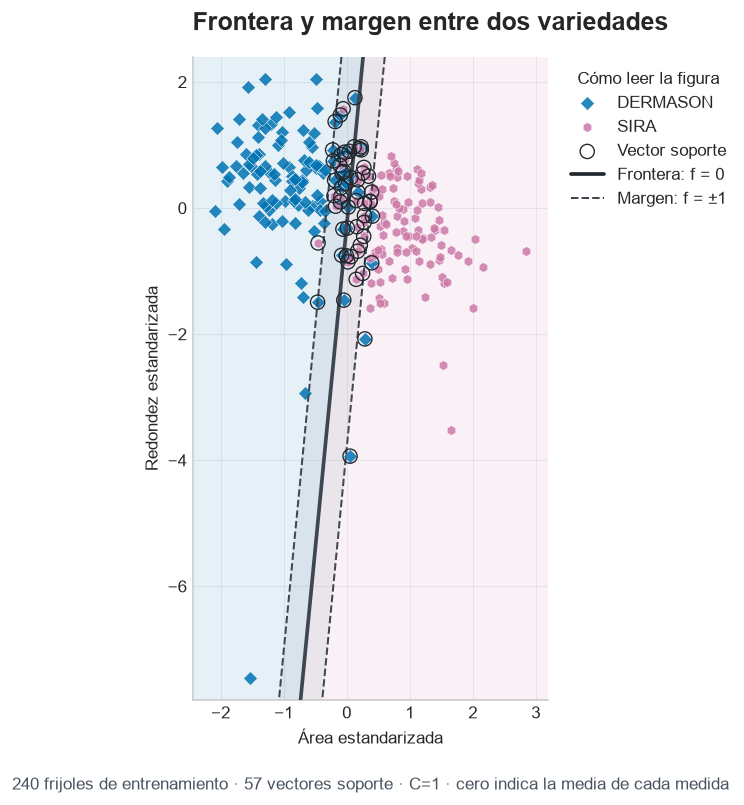

C=1 · 57 vectores soporte · ancho del margen=0.684 unidades estandarizadas.


548

In [ ]:
C_MARGEN = 1.0 # @param [0.1, 1.0, 10.0] {type:"raw"}
# Seleccionamos dos medidas físicas y etiquetamos DERMASON = –1, SIRA = +1.
columnas_margen = ['Area', 'roundness']
clases_margen = ['DERMASON', 'SIRA']
partes_margen = [X_train.loc[y_train == c, columnas_margen].sample(n=120, random_state=SEMILLA)
                for c in clases_margen]
X_margen = pd.concat(partes_margen)
y_margen = y_train.loc[X_margen.index]
y_bin_margen = np.where(y_margen.to_numpy() == 'SIRA', 1, -1)
# Centrar y escalar hace comparable una unidad horizontal con una vertical.
escalador_margen = StandardScaler().fit(X_margen)
Z_margen = escalador_margen.transform(X_margen)
svm_margen = SVC(kernel='linear', C=C_MARGEN).fit(Z_margen, y_bin_margen)

inferior = Z_margen.min(axis=0) - 0.35
superior = Z_margen.max(axis=0) + 0.35
mx, my = np.meshgrid(np.linspace(inferior[0], superior[0], 260),
                     np.linspace(inferior[1], superior[1], 220))
# El signo de f(x) determina la variedad. Los niveles ±1 delimitan el margen.
score_margen = svm_margen.decision_function(np.c_[mx.ravel(), my.ravel()]).reshape(mx.shape)
assert score_margen.min() < -1 and score_margen.max() > 1

fig, ax = plt.subplots(figsize=(9.2, 6.8))
colores_margen = [colores_bean[codigo_clase[c]] for c in clases_margen]
ax.contourf(mx, my, (score_margen >= 0).astype(int), levels=[-0.5, 0.5, 1.5],
            cmap=ListedColormap(colores_margen), alpha=0.10)
ax.contourf(mx, my, score_margen, levels=[-1, 1], colors=['#8793A1'], alpha=0.13)
for clase, signo, color, marca in zip(clases_margen, [-1, 1], colores_margen, [marcas_bean[codigo_clase[c]] for c in clases_margen]):
    mascara = y_bin_margen == signo
    ax.scatter(Z_margen[mascara, 0], Z_margen[mascara, 1], c=color, marker=marca,
               s=35, edgecolors='white', linewidths=0.35, label=clase, alpha=0.85, zorder=3)
contornos = ax.contour(mx, my, score_margen, levels=[-1, 0, 1],
                       colors=['#3D4651']*3, linestyles=['--', '-', '--'],
                       linewidths=[1.2, 2.2, 1.2], zorder=4)
# La leyenda identifica las líneas sin cubrir los frijoles próximos a la frontera.
# support_vectors_ devuelve los ejemplos que sostienen esta SVM binaria.
sv = svm_margen.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=73, facecolors='none', edgecolors='#20262D',
           linewidths=0.8, zorder=5, label='Vector soporte')
handles, etiquetas = ax.get_legend_handles_labels()
handles += [Line2D([], [], color='#20262D', linewidth=2.2, label='Frontera: f = 0'),
            Line2D([], [], color='#3D4651', linestyle='--', linewidth=1.2, label='Margen: f = ±1')]
ax.legend(handles=handles, title='Cómo leer la figura', loc='upper left',
          bbox_to_anchor=(1.02, 1), frameon=False)
ax.set(xlim=(inferior[0], superior[0]), ylim=(inferior[1], superior[1]),
       xlabel='Área estandarizada',
       ylabel='Redondez estandarizada')
ax.set_aspect('equal', adjustable='box')  # Una desviación estándar ocupa la misma longitud en ambos ejes.
ax.set_title('Frontera y margen entre dos variedades', fontsize=15, weight='bold', loc='left', pad=16)
ax.grid(color='#D8DDE3', linewidth=0.55, alpha=0.55)
ax.set_axisbelow(True)
fig.text(0.50, 0.025,
         f'{len(X_margen)} frijoles de entrenamiento · {len(sv)} vectores soporte · C={svm_margen.C:g} · cero indica la media de cada medida', ha='center',
         fontsize=10, color='#49535F')
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(SALIDA / '07_margen_y_soportes.png', dpi=180, bbox_inches='tight')
fig.savefig(SALIDA / '07_margen_y_soportes.svg', bbox_inches='tight')
plt.show()
# En coordenadas estandarizadas, la distancia entre f=-1 y f=+1 es 2/||w||.
ancho_margen = 2 / np.linalg.norm(svm_margen.coef_[0])
print(f'C={C_MARGEN:g} · {len(sv)} vectores soporte · ancho del margen={ancho_margen:.3f} unidades estandarizadas.')

resumen_visual = {
    'pca_varianza_explicada': varianza_pca.tolist(),
    'muestra_dibujada': len(posiciones_visual), 'por_clase': por_clase_visual,
    'svm_plano': {'kernel': svm_plano.kernel, 'C': svm_plano.C, 'gamma': svm_plano.gamma,
                   'accuracy_test_2d': float(accuracy_plano), 'n_test': len(X_test)},
    'svm_margen': {'kernel': svm_margen.kernel, 'C': svm_margen.C, 'n_train': len(X_margen), 'ancho_margen': float(ancho_margen),
                    'n_soportes': len(sv), 'variables': columnas_margen},
    'alcance': 'Modelos didácticos separados de la SVM principal de 16 medidas',
}
(SALIDA / 'visuales_metodologia.json').write_text(
    json.dumps(resumen_visual, indent=2, ensure_ascii=False), encoding='utf-8'
)

## Visual 4 · Animación de la clasificación de siete frijoles

Pulsa **reproducir** debajo del código. Cada frijol aparece en su posición en el mapa PCA. Antes de que se revele su identidad, intenta adivinar la variedad por la región donde cae.

El fondo muestra qué predice la SVM de **dos componentes**. El panel también muestra la decisión de la **SVM principal**, que recibe las 16 medidas originales a través de su pipeline. Después aparece la etiqueta real del dataset. La posición del frijol permanece fija mientras descubrimos esa información.

Puedes pausar al aparecer las predicciones y preguntar qué modelo acertará. Elegimos una fila de prueba por variedad para ilustrar aciertos y posibles confusiones. La exactitud global se calcula en la sección 9 con todas las filas de prueba.

[Reproducir en Drive el video de 42 segundos con la configuración original](https://drive.google.com/file/d/153eeHEhQ8n929inc13vasCGAHTrp-oV8/view?usp=drivesdk)

[Ver cómo deciden OvO y OvR para este mismo BARBUNYA](#scrollTo=svm-guia-votacion)

In [ ]:
# Cada fila de prueba tiene dos predicciones y una etiqueta que revelamos al final.
prueba_anim = pd.DataFrame({
    'posicion': np.arange(len(X_test)),
    'fila': X_test.index.to_numpy(),
    'plano': pred_plano_test,
    'completa': y_pred,
    'real': y_test.to_numpy(),
})

# Usamos el mismo encuadre que en el mapa de fronteras.
inferior_anim, superior_anim = limites_visual
en_mapa = np.all((Z_test >= inferior_anim) & (Z_test <= superior_anim), axis=1)
visibles = prueba_anim.loc[en_mapa]

# Mostramos una variedad por turno. Los dos últimos ejemplos ilustran desacuerdos
# y errores cuando los hay. Son casos elegidos para explicar, no para medir exactitud.
orden_anim = ['BOMBAY', 'SEKER', 'CALI', 'HOROZ', 'SIRA', 'BARBUNYA', 'DERMASON']
ejemplos_anim = []
for variedad in orden_anim:
    candidatos = visibles[visibles['real'] == variedad]
    acierta_plano = candidatos['plano'] == variedad
    acierta_completa = candidatos['completa'] == variedad
    preferidos = candidatos[acierta_plano & acierta_completa]
    if variedad == 'BARBUNYA':
        preferidos = candidatos[~acierta_plano & acierta_completa]
    elif variedad == 'DERMASON':
        preferidos = candidatos[(candidatos['plano'] == 'SIRA') & (candidatos['completa'] == 'SIRA')]
    # Si cambias la partición o el modelo, todavía se puede mostrar cada variedad.
    opciones = preferidos if not preferidos.empty else candidatos
    ejemplos_anim.append(opciones.iloc[0])
casos_anim = pd.DataFrame(ejemplos_anim).reset_index(drop=True)

In [ ]:
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter, writers
from matplotlib.lines import Line2D
from IPython.display import Image, Video
from subprocess import CalledProcessError

# Dibujamos el mapa una vez. Los siete frijoles comparten las mismas coordenadas PCA.
fig_anim = plt.figure(figsize=(11.4, 6.4), facecolor='white')
mapa = fig_anim.add_axes([0.075, 0.215, 0.495, 0.57])
panel = fig_anim.add_axes([0.62, 0.19, 0.36, 0.61])
panel.set(xlim=(0, 1), ylim=(0, 1))
panel.axis('off')
tinta = '#182E39'
gris = '#485B67'
fig_anim.text(0.048, 0.925, '¿Qué variedad predice la SVM?',
              fontsize=25, weight='bold', color=tinta)
paso_texto = fig_anim.text(0.05, 0.86, '', fontsize=13, color=gris)

# El fondo representa las decisiones de la SVM ajustada con dos componentes.
mapa.grid(False)
mapa.pcolormesh(malla_x, malla_y, regiones, cmap=paleta_bean,
                vmin=-0.5, vmax=len(CLASES)-0.5, shading='nearest', alpha=0.22)
for clase in CLASES:
    region = regiones == codigo_clase[clase]
    if region.any() and not region.all():
        mapa.contour(malla_x, malla_y, region.astype(int), levels=[0.5],
                     colors='#52656A', linewidths=0.55)
mapa.scatter(*Z_muestra.T, s=6, c='#536169', alpha=0.20, linewidths=0)
mapa.set(xlim=(limites_visual[0][0], limites_visual[1][0]),
         ylim=(limites_visual[0][1], limites_visual[1][1]),
         xlabel='Componente 1 (PCA)', ylabel='Componente 2 (PCA)')
mapa.tick_params(labelsize=9)
# Al terminar un caso, su símbolo queda en el mapa para comparar las siete posiciones.
clasificados = []
for caso_previo in casos_anim.itertuples(index=False):
    k = codigo_clase[caso_previo.real]
    x_previo, y_previo = Z_test[caso_previo.posicion]
    simbolo, = mapa.plot(x_previo, y_previo, linestyle='', marker=marcas_bean[k],
                         color=colores_bean[k], ms=8, mec='white', mew=0.6,
                         visible=False, zorder=6)
    clasificados.append(simbolo)
leyenda = [Line2D([], [], linestyle='', marker=marca, color=color, label=clase)
           for clase, marca, color in zip(CLASES, marcas_bean, colores_bean)]
fig_anim.legend(handles=leyenda, ncol=7, loc='lower left',
                bbox_to_anchor=(0.043, 0.022), frameon=False,
                fontsize=9, handlelength=1, columnspacing=1.25)
fig_anim.text(0.05, 0.092, 'Colores de las regiones del mapa 2D',
              fontsize=9.5, color=gris)

# El anillo permite seguir el mismo punto al revelar la predicción y la etiqueta.
anillo, = mapa.plot([], [], 'o', ms=18, mfc='white', mec=tinta, mew=2, zorder=7)
punto, = mapa.plot([], [], 'o', ms=8, color=tinta, zorder=8)
ejemplo = panel.text(0, 0.92, '', fontsize=12, color=gris)
medidas = panel.text(0, 0.845, '', fontsize=10, color=gris)
etiquetas = ['Predicción del mapa · 2 componentes',
             'Predicción del modelo · 16 medidas', 'Variedad real del dataset']
valores = []
for altura, etiqueta in zip([0.77, 0.50, 0.23], etiquetas):
    panel.text(0, altura, etiqueta, fontsize=12, color=gris)
    valores.append(panel.text(0, altura-0.11, '', fontsize=20,
                              weight='bold', color=tinta))
resultado = panel.text(0, 0.005, '', fontsize=11.5, weight='bold')
pasos = ['Ubicamos un frijol de prueba en el mapa.',
         'Leemos la predicción de cada modelo.',
         'Revelamos la etiqueta real y comprobamos el resultado.']

def mostrar_paso(fotograma):
    # A cuatro fotogramas por segundo, ocho fotogramas forman un paso de dos segundos.
    paso, instante = divmod(fotograma, 8)
    numero, etapa = divmod(paso, 3)
    caso = casos_anim.iloc[numero]
    posicion = int(caso['posicion'])
    x, y_coord = Z_test[posicion]
    for i, simbolo in enumerate(clasificados):
        simbolo.set_visible(i < numero)
    anillo.set_data([x], [y_coord])
    anillo.set_markersize(18 + (7 - instante if etapa == 0 else 0))
    punto.set_data([x], [y_coord])
    clase_real = codigo_clase[caso['real']]
    punto.set_marker(marcas_bean[clase_real] if etapa == 2 else 'o')
    punto.set_color(colores_bean[clase_real] if etapa == 2 else tinta)
    paso_texto.set_text(f'Paso {etapa+1} de 3  ·  {pasos[etapa]}')
    ejemplo.set_text(f"Frijol {numero+1} de {len(casos_anim)}  ·  Fila {caso['fila']}")
    fila = X_test.iloc[posicion]
    medidas.set_text(f"Área {fila['Area']:.0f}   ·   Redondez {fila['roundness']:.3f}".replace('.', ','))
    for texto, columna, visible in zip(valores, ['plano', 'completa', 'real'],
                                      [etapa >= 1, etapa >= 1, etapa == 2]):
        texto.set_text(caso[columna] if visible else '—')
        texto.set_color(tinta if visible else '#A3AEB4')
    acierto = caso['completa'] == caso['real']
    resultado.set_text(('El modelo de 16 medidas acertó.' if acierto else
                        'El modelo de 16 medidas se equivocó.') if etapa == 2 else '')
    resultado.set_color('#14644F' if acierto else '#944C24')

animacion = FuncAnimation(fig_anim, mostrar_paso, frames=len(casos_anim)*24,
                          interval=250, repeat=False, cache_frame_data=False)
archivo_anim = SALIDA / '08_clasificacion_animada.mp4'
try:
    if not writers.is_available('ffmpeg'):
        raise FileNotFoundError('FFmpeg')
    escritor = FFMpegWriter(fps=4, codec='libx264',
                            extra_args=['-r', '12', '-pix_fmt', 'yuv420p', '-movflags', '+faststart'])
    animacion.save(archivo_anim, writer=escritor, dpi=100)
    reproductor = Video(str(archivo_anim), embed=True, width=960,
                        html_attributes='controls playsinline preload="metadata" style="max-width:100%;height:auto"')
except (FileNotFoundError, CalledProcessError, BrokenPipeError):
    # Si el entorno carece del codificador de video, preservamos las etapas en un GIF.
    archivo_anim = SALIDA / '08_clasificacion_animada.gif'
    animacion.save(archivo_anim, writer=PillowWriter(fps=4), dpi=82)
    reproductor = Image(filename=str(archivo_anim))
plt.close(fig_anim)
display(reproductor)

## Visual 5 · Cómo se ajustan la frontera y el margen

Observa el entrenamiento de una SVM lineal con los 240 frijoles de Visual 3. Los rombos DERMASON y los hexágonos SIRA mantienen su área y redondez. El algoritmo SMO ajusta el peso de dos ejemplos en cada actualización. La película toma momentos del mismo entrenamiento.

**Para la expo.** Sigue primero la línea continua con el cursor. Cuando cambia de posición o gira, también cambia la variedad predicha para algunas combinaciones de área y redondez. Al final, recorre la distancia perpendicular entre las dos líneas discontinuas para señalar el ancho del margen. Después apunta a un frijol con anillo: su peso final es positivo y participa en la decisión. Durante el ajuste, el conjunto de puntos con peso positivo todavía puede cambiar.

En los pasos intermedios, la orientación sale de los pesos que registró SMO y la posición se dibuja estimando el sesgo con la regla del solver. El último paso usa el sesgo final del entrenamiento. [Ver este video en Drive con los parámetros originales](https://drive.google.com/file/d/18iID3Q06x7kiFNv153RQWnj2uQsVzREG/view?usp=drivesdk) Puedes pausar en **0:19** (frontera), **0:24** (ancho del margen) y **0:29** (un vector de soporte) en esta grabación.

In [ ]:
# @title Implementación SMOBinary del repositorio (expandir para explicar)
"""Implementación didáctica de SVM binaria mediante SMO.

El criterio de trabajo sigue la idea de *maximum violating pair*:
se eligen los índices que maximizan la brecha ``m - M`` de KKT y se
actualizan dos multiplicadores a la vez. La implementación permite comprobar
numéricamente la solución dual y las condiciones KKT en conjuntos pequeños.
"""

from __future__ import annotations

from itertools import combinations

import numpy as np


class SMOBinary:
    """SVM binaria con kernels lineal, polinomial y RBF."""

    def __init__(
        self,
        C: float = 1.0,
        kernel: str = "rbf",
        gamma: float = 0.1,
        degree: int = 3,
        coef0: float = 1.0,
        tol: float = 1e-3,
        max_iter: int = 20_000,
    ):
        if C <= 0:
            raise ValueError("C debe ser positivo")
        if kernel not in {"linear", "poly", "rbf"}:
            raise ValueError("kernel debe ser 'linear', 'poly' o 'rbf'")
        self.C = float(C)
        self.kernel = kernel
        self.gamma = float(gamma)
        self.degree = int(degree)
        self.coef0 = float(coef0)
        self.tol = float(tol)
        self.max_iter = int(max_iter)

    def _kernel(self, X: np.ndarray, Y: np.ndarray) -> np.ndarray:
        dot = X @ Y.T
        if self.kernel == "linear":
            return dot
        if self.kernel == "poly":
            return (self.gamma * dot + self.coef0) ** self.degree
        x2 = np.sum(X * X, axis=1)[:, None]
        y2 = np.sum(Y * Y, axis=1)[None, :]
        distances = np.maximum(x2 + y2 - 2.0 * dot, 0.0)
        # RBF da similitud 1 para un punto consigo mismo y valores menores al aumentar la distancia.
        return np.exp(-self.gamma * distances)

    def _working_sets(self, alpha: np.ndarray, y: np.ndarray):
        eps = 1e-10
        i_up = ((y == 1) & (alpha < self.C - eps)) | ((y == -1) & (alpha > eps))
        i_low = ((y == 1) & (alpha > eps)) | ((y == -1) & (alpha < self.C - eps))
        return i_up, i_low

    def fit(self, X, y, *, al_actualizar=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y):
            raise ValueError("X debe ser bidimensional y coincidir con y")
        if set(np.unique(y)) != {-1.0, 1.0}:
            raise ValueError("y debe contener exactamente las etiquetas {-1, +1}")

        n = len(y)
        # K compara cada pareja de frijoles. Con n ejemplos almacena n por n similitudes.
        K = self._kernel(X, X)
        Q = np.outer(y, y) * K
        # Cada alfa pondera un ejemplo. Empezar en cero satisface los límites y la igualdad del dual.
        alpha = np.zeros(n, dtype=float)
        gradient = -np.ones(n, dtype=float)  # Q @ alpha - 1
        gap_history = []        # residuo KKT global m - M al inicio de cada iteración
        pair_gap_history = []   # diferencia r_i - r_j del par efectivamente actualizado
        dual_history = []       # D(alpha) al inicio de cada iteración
        termination_reason = "max_iter"

        for iteration in range(1, self.max_iter + 1):
            i_up, i_low = self._working_sets(alpha, y)
            score = -y * gradient
            up_indices = np.flatnonzero(i_up)
            low_indices = np.flatnonzero(i_low)
            i = int(up_indices[np.argmax(score[up_indices])])
            m = float(score[i])
            # Residuo global: M es el mínimo sobre todo I_low, no el del candidato.
            gap_history.append(m - float(np.min(score[low_indices])))
            # D = 1'a - a'Qa/2 = (1'a - a'G)/2, con G = Qa - 1: costo O(n).
            dual_history.append(0.5 * (alpha.sum() - alpha @ gradient))

            # Probar primero los candidatos con menor puntuación. Los pares
            # con eta cero también pueden mejorar el objetivo dual.
            candidates = low_indices[np.argsort(score[low_indices])]
            updated = False
            for j_value in candidates:
                j = int(j_value)
                if j == i:
                    continue
                M = float(score[j])
                gap = m - M
                if gap <= self.tol:
                    # Un candidato sin violación no certifica a los anteriores
                    # que pudieron descartarse. Comprobar KKT global al final.
                    break

                eta = float(K[i, i] + K[j, j] - 2.0 * K[i, j])

                # Dirección factible: Δalpha_i=t*y_i, Δalpha_j=-t*y_j.
                lower_i, upper_i = (
                    (-alpha[i], self.C - alpha[i])
                    if y[i] == 1
                    else (alpha[i] - self.C, alpha[i])
                )
                lower_j, upper_j = (
                    (alpha[j] - self.C, alpha[j])
                    if y[j] == 1
                    else (-alpha[j], self.C - alpha[j])
                )
                lower = max(lower_i, lower_j)
                upper = min(upper_i, upper_j)
                if upper - lower <= 1e-14:
                    continue

                # Ganancia dual: gap*t - eta*t**2/2. Una eta positiva,
                # por pequeña que sea, conserva la solución cuadrática.
                if eta > 0.0:
                    # Evitar dividir por una eta minúscula si el máximo libre
                    # queda fuera del intervalo factible (gap > 0, upper >= 0).
                    step = float(upper if gap >= eta * upper else np.clip(gap / eta, lower, upper))
                elif eta == 0.0:
                    step = float(upper)
                else:
                    # Curvatura negativa: comparar extremos y conservar cero
                    # como opción. Con un kernel PSD, eta no es negativa en
                    # aritmética exacta; aquí puede haber error numérico.
                    step = max(
                        (0.0, float(lower), float(upper)),
                        key=lambda t: t * (gap - 0.5 * eta * t),
                    )
                if abs(step) <= 1e-14:
                    continue
                # Los dos cambios se compensan en la suma de alfa por etiqueta, que debe seguir valiendo cero.
                delta_i = step * y[i]
                delta_j = -step * y[j]
                alpha[i] += delta_i
                alpha[j] += delta_j
                gradient += Q[:, i] * delta_i + Q[:, j] * delta_j
                pair_gap_history.append(gap)
                # Un observador opcional guarda los pesos tras cada actualización del par.
                if al_actualizar is not None:
                    al_actualizar(iteration, alpha.copy())
                updated = True
                break

            if not updated:
                termination_reason = "stalled"
                break

        # Recalcular desde alpha evita certificar con un gradiente acumulado
        # que puede haber sufrido deriva numérica.
        gradient = Q @ alpha - 1.0
        i_up, i_low = self._working_sets(alpha, y)
        score = -y * gradient
        m = float(np.max(score[i_up]))
        M = float(np.min(score[i_low]))
        # Los soportes con 0 < alfa < C sirven para estimar el sesgo de la frontera.
        free = (alpha > 1e-8) & (alpha < self.C - 1e-8)
        b = float(np.median(score[free])) if np.any(free) else (m + M) / 2.0

        z = alpha * y
        self.X_ = X
        self.y_ = y
        self.alpha_ = alpha
        self.b_ = b
        self.support_ = np.flatnonzero(alpha > 1e-8)
        self.n_iter_ = iteration
        self.m_ = m
        self.M_ = M
        self.kkt_gap_ = m - M
        self.equality_residual_ = float(abs(alpha @ y))
        self.dual_objective_ = float(alpha.sum() - 0.5 * z @ K @ z)
        # Factibilidad a escala de redondeo; tol sigue siendo la tolerancia KKT.
        roundoff = 64.0 * np.finfo(float).eps
        box_tol = roundoff * max(1.0, self.C)
        equality_tol = roundoff * max(1.0, float(np.abs(alpha).sum()))
        self.converged_ = bool(
            np.all(np.isfinite(alpha))
            and np.all(np.isfinite(gradient))
            and np.isfinite(b)
            and np.isfinite(self.dual_objective_)
            and np.all(alpha >= -box_tol)
            and np.all(alpha <= self.C + box_tol)
            and self.equality_residual_ <= equality_tol
            and self.kkt_gap_ <= self.tol
        )
        self.termination_reason_ = "converged" if self.converged_ else termination_reason
        # Se añade el residuo final para que la curva termine en el valor certificado.
        self.gap_history_ = np.asarray(gap_history + [self.kkt_gap_])
        self.pair_gap_history_ = np.asarray(pair_gap_history)
        self.dual_history_ = np.asarray(dual_history + [self.dual_objective_])
        return self

    def pointwise_kkt_violation(self, box_tol: float = 1e-8) -> float:
        """Máxima violación KKT puntual usando el sesgo realmente devuelto.

        alpha=0 exige t>=1; 0<alpha<C exige t=1; alpha=C exige t<=1,
        con t_i = y_i f(x_i). Devuelve el máximo sobre i.
        """
        t = self.y_ * self.decision_function(self.X_)
        at_zero = self.alpha_ <= box_tol
        at_c = self.alpha_ >= self.C - box_tol
        free = ~(at_zero | at_c)
        viol = np.zeros_like(t)
        viol[at_zero] = np.maximum(0.0, 1.0 - t[at_zero])
        viol[at_c] = np.maximum(0.0, t[at_c] - 1.0)
        viol[free] = np.abs(1.0 - t[free])
        return float(viol.max())

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        # Para predecir, cada soporte aporta su similitud con el nuevo frijol, su peso alfa y su etiqueta.
        sv = self.support_
        return self._kernel(X, self.X_[sv]) @ (self.alpha_[sv] * self.y_[sv]) + self.b_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1.0, -1.0)

In [ ]:
# @title Registrar los pasos reales del entrenamiento { display-mode: "form" }
# SMO modifica dos pesos alfa por actualización. Conservamos una selección de esos pasos.
ajuste_smo = SMOBinary(kernel='linear', C=svm_margen.C, tol=1e-4)
cortes_smo = set(np.geomspace(1, ajuste_smo.max_iter, 64).round().astype(int))
historia_smo = {}

def guardar_paso_smo(numero, alfa):
    if numero in cortes_smo:
        historia_smo[numero] = alfa

ajuste_smo.fit(Z_margen, y_bin_margen, al_actualizar=guardar_paso_smo)
assert ajuste_smo.converged_, 'El solver todavía no alcanzó la tolerancia KKT.'
actualizaciones_smo = len(ajuste_smo.pair_gap_history_)
historia_smo[actualizaciones_smo] = ajuste_smo.alpha_.copy()

# Una recta se escribe como f(x) = w·x + b. w se obtiene de los alfa del paso.
# El solver calcula su b definitivo al terminar. Para dibujar antes, estimamos b
# con la misma regla: la mediana de y − Xw entre los puntos con 0 < alfa < C.
def geometria_paso_smo(alfa):
    w = (alfa * y_bin_margen) @ Z_margen
    puntuacion = y_bin_margen - Z_margen @ w
    libres = (alfa > 1e-8) & (alfa < ajuste_smo.C - 1e-8)
    if libres.any():
        b = np.median(puntuacion[libres])
    else:
        arriba, abajo = ajuste_smo._working_sets(alfa, y_bin_margen)
        b = (puntuacion[arriba].max() + puntuacion[abajo].min()) / 2
    return w, float(b)

geometrias_smo = {n: geometria_paso_smo(a) for n, a in historia_smo.items()}
w_final, b_estimado = geometrias_smo[actualizaciones_smo]
assert np.isclose(b_estimado, ajuste_smo.b_)
geometrias_smo[actualizaciones_smo] = (w_final, ajuste_smo.b_)
ancho_final_smo = 2 / np.linalg.norm(w_final)
predicciones_finales_smo = ajuste_smo.predict(Z_margen)
coincidencia_smo = np.mean(predicciones_finales_smo == svm_margen.predict(Z_margen))
print(f'{actualizaciones_smo} actualizaciones · {len(ajuste_smo.support_)} soportes · '
      f'ancho {ancho_final_smo:.3f} · residuo KKT {ajuste_smo.kkt_gap_:.2g}')
print(f'Concordancia con la SVM lineal del Visual 3 en los {len(Z_margen)} frijoles: {coincidencia_smo:.1%}.')

244 actualizaciones · 57 soportes · ancho 0.684 · residuo KKT 8.1e-05
Concordancia con la SVM lineal del Visual 3 en los 240 frijoles: 100.0%.


In [ ]:
# @title Reproducir el ajuste de la frontera y del margen { display-mode: "form" }
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter, writers
from matplotlib.lines import Line2D
from IPython.display import Video, Image

# Se muestran actualizaciones reales, espaciadas para poder observar el inicio y el final.
claves_smo = list(historia_smo)
indices_pelicula = np.linspace(0, len(claves_smo)-1, min(15, len(claves_smo))).round().astype(int)
pasos_pelicula = [claves_smo[i] for i in indices_pelicula]
escenas_smo = [('inicio', 0)] * 3
escenas_smo += [('ajuste', n) for n in pasos_pelicula if n < actualizaciones_smo]
for tema in ['frontera', 'margen', 'soportes']:
    escenas_smo.extend([(tema, actualizaciones_smo)] * 5)

fig_smo = plt.figure(figsize=(11.2, 6.6), facecolor='white')
plano_smo = fig_smo.add_axes([0.035, 0.125, 0.51, 0.67])
texto_smo = fig_smo.add_axes([0.54, 0.10, 0.435, 0.68])
texto_smo.axis('off')
tinta_smo = '#173541'
acento_smo = '#A44F21'
fig_smo.text(0.052, 0.921, 'Cómo aprende la frontera una SVM', fontsize=25, weight='bold', color=tinta_smo)
fig_smo.text(0.054, 0.858, 'Dos variedades  ·  Área y redondez  ·  SVM lineal con SMO',
             fontsize=13, color='#405A66')

# En estos ejes una unidad tiene la misma longitud horizontal y vertical.
plano_smo.set_aspect('equal', adjustable='box')
lim_inf_smo = Z_margen.min(axis=0) - [0.7, 0.40]
lim_sup_smo = Z_margen.max(axis=0) + [0.7, 0.40]
plano_smo.set(xlim=(lim_inf_smo[0], lim_sup_smo[0]), ylim=(lim_inf_smo[1], lim_sup_smo[1]),
              xlabel='Área estandarizada', ylabel='Redondez estandarizada')
plano_smo.tick_params(labelsize=9)
plano_smo.grid(color='#DFE6E7', lw=0.6)
plano_smo.set_axisbelow(True)
for clase, signo in [('DERMASON', -1), ('SIRA', 1)]:
    puntos = Z_margen[y_bin_margen == signo]
    k = codigo_clase[clase]
    plano_smo.scatter(*puntos.T, color=colores_bean[k], marker=marcas_bean[k],
                      s=25, ec='white', lw=0.4, label=clase, zorder=3)
plano_smo.legend(loc='lower left', bbox_to_anchor=(-0.015, 1.005), ncol=2,
                 frameon=False, handlelength=1, columnspacing=1.1, fontsize=10)

lineas_smo = []
for nivel in [-1, 0, 1]:
    linea, = plano_smo.plot([], [], color=tinta_smo, ls='-' if nivel == 0 else '--',
                            lw=2.4 if nivel == 0 else 1.3, zorder=4)
    lineas_smo.append(linea)
aros_smo = plano_smo.scatter([], [], s=61, facecolors='none', edgecolors=tinta_smo,
                             linewidths=0.85, zorder=5)
flecha_ancho = plano_smo.annotate('', xy=(0, 0), xytext=(0, 0), zorder=7,
                                 arrowprops=dict(arrowstyle='<->', color=acento_smo,
                                                 lw=2.2, shrinkA=0, shrinkB=0))
rotulo_smo = plano_smo.annotate('', xy=(0, 0), xytext=(0.96, 0.24), textcoords='axes fraction',
                               color=acento_smo, ha='right', weight='bold', fontsize=10,
                               bbox=dict(facecolor='white', edgecolor='none', pad=2),
                               arrowprops=dict(arrowstyle='->', color=acento_smo), zorder=8)
etapa_smo = texto_smo.text(0, 0.99, '', color=acento_smo, fontsize=13, weight='bold', va='top')
titulo_smo = texto_smo.text(0, 0.865, '', color=tinta_smo, fontsize=21, weight='bold', va='top')
relato_smo = texto_smo.text(0, 0.735, '', color=tinta_smo, fontsize=13.5, va='top', linespacing=1.45)
detalle_smo = texto_smo.text(0, 0.409, '', color=tinta_smo, fontsize=13, va='top', linespacing=1.5)
leyenda_smo = [Line2D([], [], color=tinta_smo, lw=2.5, label='Frontera de decisión'),
               Line2D([], [], color=tinta_smo, lw=1.3, ls='--', label='Bordes del margen'),
               Line2D([], [], ls='', marker='o', mfc='white', mec=tinta_smo, ms=8,
                      label='Frijol con peso positivo')]
texto_smo.legend(handles=leyenda_smo, loc='lower left', borderaxespad=0,
                 frameon=False, fontsize=11, labelspacing=0.52)
frases_smo = {
    'inicio': ('Frijoles de entrenamiento', 'El color indica la variedad real.\nLos frijoles permanecen en su posición.\nTodos sus pesos empiezan en cero.'),
    'ajuste': ('Una recta provisional', 'SMO actualiza dos pesos a la vez.\nLos anillos muestran qué frijoles tienen\npeso positivo en este paso.'),
    'frontera': ('La frontera', 'Al cruzar la línea continua cambia\nla variedad predicha. En la línea,\nla función de decisión vale cero.'),
    'margen': ('El ancho del margen', 'Las líneas discontinuas son los bordes.\nLa flecha mide la distancia más corta\nentre ellas, perpendicular a la frontera.'),
    'soportes': ('Los vectores de soporte', 'Los frijoles con anillo conservan peso\nen la solución final y determinan la recta.\nAlgunos pueden quedar mal clasificados.'),
}

def dibujar_ajuste_smo(segundo):
    tema, n = escenas_smo[segundo]
    titulo, relato = frases_smo[tema]
    titulo_smo.set_text(titulo)
    relato_smo.set_text(relato)
    terminado = tema in ('frontera', 'margen', 'soportes')
    etapa_smo.set_text('SOLUCIÓN FINAL' if terminado else f'ACTUALIZACIÓN {n} DE {actualizaciones_smo}')
    rotulo_smo.set_visible(terminado)
    flecha_ancho.set_visible(tema == 'margen')
    if tema == 'inicio':
        for linea in lineas_smo:
            linea.set_data([], [])
        aros_smo.set_offsets(np.empty((0, 2)))
        detalle_smo.set_text(f'{len(Z_margen)} frijoles de entrenamiento\nC = {ajuste_smo.C:g}')
        return

    # Cada recta satisface w·x + b = nivel, con niveles −1, 0 y 1.
    w, b = geometrias_smo[n]
    norma = np.linalg.norm(w)
    if norma < 1e-12:  # Algunos pasos intermedios pueden carecer de dirección.
        for linea in lineas_smo:
            linea.set_data([], [])
    else:
        tangente = np.array([-w[1], w[0]]) / norma
        longitud = 2*np.linalg.norm(lim_sup_smo - lim_inf_smo)
        for linea, nivel in zip(lineas_smo, [-1, 0, 1]):
            centro = w * (nivel - b) / norma**2
            extremos = [centro - longitud*tangente, centro + longitud*tangente]
            linea.set_data(*np.asarray(extremos).T)
    activos = ajuste_smo.support_ if terminado else np.flatnonzero(historia_smo[n] > 1e-8)
    aros_smo.set_offsets(Z_margen[activos])
    ancho = f'{2/norma:.3f}'.replace('.', ',') if norma >= 1e-12 else 'sin definir'
    etiqueta = 'Vectores de soporte' if terminado else 'Pesos activos'
    detalle_smo.set_text(f'{etiqueta}    {len(activos)} de {len(Z_margen)}\nAncho del margen    {ancho}')
    if terminado:
        # Apuntamos a la zona despejada de la recta y dibujamos la perpendicular exacta.
        guia = np.array([0, lim_inf_smo[1] + 0.36*(lim_sup_smo[1]-lim_inf_smo[1])])
        centro = guia - w*(w@guia + b)/norma**2
        radio = w/norma**2
        flecha_ancho.xy = centro + radio
        flecha_ancho.set_position(centro - radio)
        rotulo_smo.xy = centro
        rotulo_smo.set_text({'frontera':'Frontera', 'margen':'Margen', 'soportes':'Soporte'}[tema])
        if tema == 'margen':
            rotulo_smo.xy = centro + radio
        if tema == 'soportes':
            rotulo_smo.xy = Z_margen[activos[np.argmin(Z_margen[activos, 1])]]

# El reproductor permite pausar cada actualización y las tres explicaciones finales.
pelicula_smo = FuncAnimation(fig_smo, dibujar_ajuste_smo, frames=len(escenas_smo),
                             interval=1000, repeat=False, cache_frame_data=False)
if writers.is_available('ffmpeg'):
    ruta_video_smo = SALIDA / '09_entrenamiento_frontera.mp4'
    escritor_smo = FFMpegWriter(fps=1, codec='libx264',
                                extra_args=['-r', '12', '-pix_fmt', 'yuv420p', '-movflags', '+faststart'])
    pelicula_smo.save(ruta_video_smo, writer=escritor_smo, dpi=100)
    visor_smo = Video(str(ruta_video_smo), embed=True, width=960,
                      html_attributes='controls playsinline preload="metadata" style="max-width:100%;height:auto"')
else:
    ruta_video_smo = SALIDA / '09_entrenamiento_frontera.gif'
    pelicula_smo.save(ruta_video_smo, writer=PillowWriter(fps=1), dpi=84)
    visor_smo = Image(filename=str(ruta_video_smo))
plt.close(fig_smo)
display(visor_smo)

## Visual 6 · Cómo se ven las siete variedades al reunir sus medidas

Se proyectan las 16 medidas en los dos ejes PCA de Visual 1, calculados con los datos de entrenamiento. Sigue cómo aparecen los frijoles de prueba en sus coordenadas y cómo se van distinguiendo las nubes. Los colores identifican las variedades registradas en el dataset.

**Para la expo.** Al aparecer los colores, señala el grupo BOMBAY y después la zona donde se mezclan CALI y BARBUNYA. Dos frijoles cercanos en esta pantalla se parecen según estas dos componentes. El modelo principal dispone de las 16 medidas para clasificarlos.

Los puntos aparecen en orden mezclado y mantienen su posición cuando se revela su variedad. [Ver este video en Drive con los parámetros originales](https://drive.google.com/file/d/1gOfJ6tvw2ffWkn2n_eszlXiW71yMJyaS/view?usp=drivesdk) Pausa en **0:20** para ver BOMBAY y en **0:28** para ver el solapamiento entre variedades.

In [ ]:
# @title Preparar los puntos y las dos ampliaciones { display-mode: "form" }
# Mezclamos el orden en que aparecen las observaciones. Sus coordenadas ya están
# calculadas por la PCA del Visual 1 a partir de las 16 medidas de cada frijol.
orden_grupos = np.random.default_rng(SEMILLA).permutation(len(y_muestra))
puntos_grupos = Z_muestra[orden_grupos]
etiquetas_grupos = y_muestra[orden_grupos]

# Usaremos dos ventanas del mismo tamaño para comparar zonas del plano.
# Centramos la primera en el BOMBAY más cercano a la mediana de su variedad.
bombay = puntos_grupos[etiquetas_grupos == 'BOMBAY']
dist_bombay = np.linalg.norm(bombay - np.median(bombay, axis=0), axis=1)
centro_bombay = bombay[dist_bombay.argmin()]
radio_ventana = 1.0  # Una unidad de PCA a cada lado del centro en ambos ejes.

def dentro_de_ventana(centro):
    return np.all(np.abs(puntos_grupos - centro) <= radio_ventana, axis=1)

# Buscamos una ventana que muestre bien el solapamiento. Para cada candidato
# contamos CALI y BARBUNYA y elegimos donde ambas variedades tengan presencia.
candidatos_grupos = puntos_grupos[np.isin(etiquetas_grupos, ['CALI', 'BARBUNYA'])]
presencia_compartida = []
for centro in candidatos_grupos:
    etiquetas_locales = etiquetas_grupos[dentro_de_ventana(centro)]
    presencia_compartida.append(min(sum(etiquetas_locales == 'CALI'),
                                    sum(etiquetas_locales == 'BARBUNYA')))
centro_mezcla = candidatos_grupos[np.argmax(presencia_compartida)]
ventanas_grupos = [centro_bombay, centro_mezcla]

In [ ]:
# @title Reproducir cómo se forman las nubes de variedades { display-mode: "form" }
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter, writers
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from IPython.display import Image, Video
from subprocess import CalledProcessError

fig_gr, ax_gr = plt.subplots(figsize=(12, 6.8), facecolor='white')
fig_gr.subplots_adjust(left=0.08, bottom=0.21, right=0.67, top=0.79)
configurar_plano(ax_gr)
tinta_gr = '#182E39'
gris_gr = '#536571'
fig_gr.text(0.055, 0.923, '¿Cómo se distribuyen las siete variedades?',
            color=tinta_gr, fontsize=24, weight='bold')
sub_gr = fig_gr.text(0.056, 0.856, '', fontsize=13, color=gris_gr)

# Una capa gris muestra posiciones. Las siete capas de color revelan etiquetas.
grises = ax_gr.scatter([], [], s=23, c='#697885', alpha=0.61, linewidths=0)
capas_gr = [ax_gr.scatter([], [], s=35, color=color, marker=marca,
                         edgecolors='white', linewidths=0.35, zorder=3)
            for color, marca in zip(colores_bean, marcas_bean)]
leyenda_gr = fig_gr.legend(
    handles=[Line2D([], [], color=c, marker=m, linestyle='', label=nombre)
             for nombre, c, m in zip(CLASES, colores_bean, marcas_bean)],
    ncol=7, loc='lower center', bbox_to_anchor=(0.5, 0.035),
    frameon=False, fontsize=11, handlelength=1, columnspacing=1.8)

# El recuadro y la ampliación muestran exactamente la misma ventana de datos.
marco_gr = Rectangle((0, 0), 2*radio_ventana, 2*radio_ventana, fill=False,
                     ec='#152D3D', linewidth=2.0, zorder=5)
ax_gr.add_patch(marco_gr)
lupa = fig_gr.add_axes([0.727, 0.326, 0.210, 0.318], facecolor='#F7F9FB')
lupa.set_aspect('equal', adjustable='box')
lupa.set_xticks([])
lupa.set_yticks([])
for borde in lupa.spines.values():
    borde.set_visible(True)
    borde.set_color('#596B75')
    borde.set_linewidth(1)
capas_lupa = [lupa.scatter([], [], s=65, c=c, marker=m, edgecolors='white', linewidths=0.65)
              for c, m in zip(colores_bean, marcas_bean)]
cabecera_gr = fig_gr.text(0.710, 0.762, '', color=tinta_gr, weight='bold', fontsize=17)
subpanel_gr = fig_gr.text(0.711, 0.699, '', color=gris_gr, fontsize=12)
contador_gr = fig_gr.text(0.709, 0.504, '', color=tinta_gr, weight='bold', fontsize=31)
pie_gr = fig_gr.text(0.711, 0.265, '', color=gris_gr, fontsize=12, va='top', linespacing=1.6)
etapas_gr = [
    'Aparecen frijoles de prueba en sus coordenadas PCA.',
    'Revelamos el color y el símbolo de la variedad real.',
    'Observa el grupo dorado y su ampliación a la derecha.',
    'Compara dos variedades que comparten una zona del plano.',
]

def mostrar_grupos(frame):
    # A 4 fotogramas por segundo: posiciones (0–8 s), etiquetas (8–16 s),
    # BOMBAY (16–24 s) y el solapamiento CALI–BARBUNYA (24–32 s).
    etapa, paso = divmod(frame, 32)
    total = len(puntos_grupos)
    # La aparición gradual dura 6 s y el resultado se mantiene para explicarlo.
    avance = min(1, (paso + 1) / 24)
    dibujados = int(np.ceil(total*avance)) if etapa == 0 else total
    en_color = total
    if etapa == 0:
        en_color = 0
    elif etapa == 1:
        en_color = int(np.ceil(total*avance))
    grises.set_offsets(puntos_grupos[en_color:dibujados])
    sub_gr.set_text(etapas_gr[etapa])
    leyenda_gr.set_visible(etapa >= 1)
    ampliar = etapa >= 2
    marco_gr.set_visible(ampliar)
    lupa.set_visible(ampliar)
    contador_gr.set_visible(not ampliar)
    if ampliar:
        centro = ventanas_grupos[etapa - 2]
        dentro = dentro_de_ventana(centro)
        marco_gr.set_xy(centro - radio_ventana)
        lupa.set_xlim(centro[0]-radio_ventana, centro[0]+radio_ventana)
        lupa.set_ylim(centro[1]-radio_ventana, centro[1]+radio_ventana)
        destacadas = ['BOMBAY'] if etapa == 2 else ['CALI', 'BARBUNYA']
        cabecera_gr.set_text(' y '.join(destacadas))
        subpanel_gr.set_text('Ampliación del recuadro')
        # Los conteos salen de los mismos puntos que aparecen en la ampliación.
        locales = etiquetas_grupos[dentro]
        detalle = '   ·   '.join(f'{sum(locales == c)} {c}' for c in destacadas)
        otros = locales[~np.isin(locales, destacadas)]
        if otros.size:
            otras_clases, cantidades = np.unique(otros, return_counts=True)
            detalle += '\n' + '   ·   '.join(f'{n} {c}' for c, n in zip(otras_clases, cantidades))
        pie_gr.set_text(f'{len(locales)} frijoles en el recuadro\n{detalle}')
    else:
        cabecera_gr.set_text('Frijoles en el mapa' if etapa == 0 else 'Variedades reveladas')
        subpanel_gr.set_text('Observaciones dibujadas' if etapa == 0 else 'Frijoles con etiqueta visible')
        contador_gr.set_text(f'{dibujados if etapa == 0 else en_color} / {total}')
        variacion = f'{varianza_pca.sum():.1%}'.replace('.', ',')
        pie_gr.set_text(f'Dos ejes resumen el {variacion}\nde la variabilidad de las 16 medidas.'
                        if etapa == 0 else f'{por_clase_visual} frijoles de prueba por variedad.')
    for i, clase in enumerate(CLASES):
        esta_clase = etiquetas_grupos[:en_color] == clase
        capas_gr[i].set_offsets(puntos_grupos[:en_color][esta_clase])
        capas_gr[i].set_alpha(0.90 if not ampliar or clase in destacadas else 0.13)
        if ampliar:
            capas_lupa[i].set_offsets(puntos_grupos[dentro & (etiquetas_grupos == clase)])
            capas_lupa[i].set_alpha(0.90 if clase in destacadas else 0.32)

pelicula_gr = FuncAnimation(fig_gr, mostrar_grupos, frames=128, interval=250,
                            repeat=False, cache_frame_data=False)
archivo_gr = SALIDA / '10_agrupacion_pca.mp4'
try:
    if not writers.is_available('ffmpeg'):
        raise FileNotFoundError('FFmpeg')
    writer_gr = FFMpegWriter(fps=4, codec='libx264',
                             extra_args=['-r', '12', '-pix_fmt', 'yuv420p', '-movflags', '+faststart'])
    pelicula_gr.save(archivo_gr, writer=writer_gr, dpi=100)
    reproductor_gr = Video(str(archivo_gr), embed=True, width=960,
                           html_attributes='controls playsinline preload="metadata" style="max-width:100%;height:auto"')
except (FileNotFoundError, CalledProcessError, BrokenPipeError):
    archivo_gr = archivo_gr.with_suffix('.gif')
    pelicula_gr.save(archivo_gr, writer=PillowWriter(fps=4), dpi=80)
    reproductor_gr = Image(filename=str(archivo_gr))
plt.close(fig_gr)
display(reproductor_gr)

## Visual 7 · Cómo deciden OvO y OvR para el mismo BARBUNYA

Sigue el sexto frijol del Visual 4. En esta comparación los dos modelos reciben las mismas 16 medidas. Se usa la misma partición de entrenamiento, el mismo escalado y los mismos parámetros de la SVM.

**OvO, uno contra uno.** Cada casilla compara la variedad de su fila con la de su columna. El clasificador de esa pareja da un voto a una de las dos variedades. Hay 21 parejas distintas. Cada variedad participa en seis duelos, así que puede recibir hasta seis votos.

**OvR, uno contra el resto.** Entrenamos siete SVM binarias. Una compara BARBUNYA con las otras seis, otra compara BOMBAY con el resto, y así sucesivamente. Cada SVM devuelve una puntuación de decisión. Un valor positivo favorece a su variedad y uno negativo favorece al resto. OvR elige la variedad con la puntuación más alta.

Pulsa **reproducir** debajo del código. También puedes desplegar la tabla de las 21 parejas para consultar cualquier voto durante la exposición.

**Pausas para la expo.** En **0:04** aparece BARBUNYA frente a CALI. En **0:25** ya se repartieron los 21 votos. En **0:45** aparecen el recuento de OvO y las siete puntuaciones de OvR, cada uno en su propia escala. [Reproducir la animación en Drive](https://drive.google.com/file/d/1krRqPUfWFPLDbtVCx_-whPJPWxNO5UWq/view?usp=drivesdk) Para recalcularla desde una sesión nueva, elige **Entorno de ejecución → Ejecutar todas**.

In [ ]:
# @title Calcular los 21 votos OvO y entrenar los siete clasificadores OvR { display-mode: "form" }
from copy import copy
from itertools import combinations
from sklearn.base import clone
from sklearn.multiclass import OneVsRestClassifier

# Recuperamos el mismo BARBUNYA de prueba que apareció en el Visual 4.
caso_votos = casos_anim.loc[casos_anim['real'] == 'BARBUNYA'].iloc[0]
fila_votos = int(caso_votos['fila'])
frijol_votos = X_test.loc[[fila_votos]]
real_votos = str(y_test.loc[fila_votos])
assert real_votos == caso_votos['real']

# El escalador ya aprendió sus parámetros con X_train. Ambos métodos reciben
# las mismas 16 medidas transformadas y entrenan con las mismas filas.
preparacion_votos = modelo[:-1]
x_frijol_votos = preparacion_votos.transform(frijol_votos)
svm_principal = modelo.named_steps['svm']
clases_votos = svm_principal.classes_.tolist()

# SVC ya entrenó un clasificador por pareja. En una copia pedimos las 21
# decisiones originales, ordenadas como las combinaciones de sus siete clases.
lector_ovo = copy(svm_principal)
lector_ovo.decision_function_shape = 'ovo'
decisiones_pares = lector_ovo.decision_function(x_frijol_votos)[0]
parejas = list(combinations(clases_votos, 2))
assert len(decisiones_pares) == len(parejas)
duelos_votos = []
conteo_ovo = dict.fromkeys(clases_votos, 0)
for (primera, segunda), decision in zip(parejas, decisiones_pares):
    # En la salida multiclase por parejas de SVC, el signo positivo favorece
    # a la primera variedad. Si vale cero, LIBSVM concede el voto a la segunda.
    elegida = primera if decision > 0 else segunda
    duelos_votos.append((primera, segunda, elegida))
    conteo_ovo[elegida] += 1

ganadora_ovo = str(modelo.predict(frijol_votos)[0])
assert sum(conteo_ovo.values()) == len(parejas)
assert conteo_ovo[ganadora_ovo] == max(conteo_ovo.values())
if not svm_principal.break_ties:
    # Ante empate de votos, SVC por defecto elige la primera clase empatada.
    assert ganadora_ovo == max(clases_votos, key=conteo_ovo.get)

# OvR sí requiere siete entrenamientos binarios nuevos. En cada uno, la
# variedad elegida es positiva y todas las otras variedades forman el resto.
modelo_ovr = OneVsRestClassifier(clone(svm_principal))
modelo_ovr.fit(preparacion_votos.transform(X_train), y_train)
assert modelo_ovr.classes_.tolist() == clases_votos
puntos_ovr = modelo_ovr.decision_function(x_frijol_votos)[0]
ganadora_ovr = str(modelo_ovr.predict(x_frijol_votos)[0])
assert puntos_ovr[clases_votos.index(ganadora_ovr)] == puntos_ovr.max()

print(f'Fila limpia {fila_votos} · Etiqueta real {real_votos}')
print(f'Predicción OvO: {ganadora_ovo} · Predicción OvR: {ganadora_ovr}')
display(pd.DataFrame({
    'Variedad': clases_votos,
    'Votos OvO': [conteo_ovo[c] for c in clases_votos],
    'Puntuación OvR': puntos_ovr.round(3),
}).set_index('Variedad'))

# Se puede desplegar el detalle de los duelos mientras se explica un voto.
from IPython.display import HTML
tabla_parejas = pd.DataFrame(duelos_votos, columns=['Primera', 'Segunda', 'Ganadora'])
display(HTML('<details><summary>Ver las 21 parejas y sus votos</summary>'
             + tabla_parejas.to_html(index=False) + '</details>'))

Fila limpia 2257 · Etiqueta real BARBUNYA
Predicción OvO: BARBUNYA · Predicción OvR: BARBUNYA


,Votos OvO,Puntuación OvR
Variedad,,
BARBUNYA,6,1.474
BOMBAY,0,-5.235
CALI,5,-2.147
DERMASON,1,-11.362
HOROZ,4,-0.890
SEKER,2,-3.528
SIRA,3,-6.346


Primera,Segunda,Ganadora
BARBUNYA,BOMBAY,BARBUNYA
BARBUNYA,CALI,BARBUNYA
BARBUNYA,DERMASON,BARBUNYA
BARBUNYA,HOROZ,BARBUNYA
BARBUNYA,SEKER,BARBUNYA
BARBUNYA,SIRA,BARBUNYA
BOMBAY,CALI,CALI
BOMBAY,DERMASON,DERMASON
BOMBAY,HOROZ,HOROZ
BOMBAY,SEKER,SEKER


In [ ]:
# @title Ver la votación y comparar OvO con OvR { display-mode: "form" }
# Cada segundo de la película corresponde a una escena. Se puede pausar en cada duelo.
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter, writers
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from IPython.display import Image, Video
from subprocess import CalledProcessError

fig_votos = plt.figure(figsize=(12.8, 7.2), facecolor='white')
color_votos = dict(zip(CLASES, colores_bean))
orden_votos = {clase: i for i, clase in enumerate(clases_votos)}
n_votos = len(clases_votos)
tinta_votos = '#173541'
gris_votos = '#48616D'

# Guardamos el marcador después de cada duelo. Solo una variedad gana el voto de cada pareja.
marcadores = np.zeros((len(duelos_votos) + 1, n_votos), dtype=int)
for k, (_, _, ganadora) in enumerate(duelos_votos, start=1):
    marcadores[k] = marcadores[k-1]
    marcadores[k, orden_votos[ganadora]] += 1

def decimal_votos(numero):
    return f'{numero:+.2f}'.replace('.', ',')

def matriz_de_parejas(cantidad):
    ax = fig_votos.add_axes([0.131, 0.163, 0.405, 0.505])
    ax.set(xlim=(-0.5, n_votos-0.5), ylim=(n_votos-0.5, -0.5))
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set_xticks(range(n_votos), [c[:3] for c in clases_votos])
    ax.set_yticks(range(n_votos), clases_votos)
    ax.xaxis.tick_top()
    ax.tick_params(length=0, labelsize=10, pad=5)
    for k, (primera, segunda, ganadora) in enumerate(duelos_votos):
        i, j = orden_votos[primera], orden_votos[segunda]
        revelada = k < cantidad
        # Las iniciales identifican a la ganadora incluso sin distinguir los colores.
        fondo = 0.73 + 0.27*np.array(to_rgb(color_votos[ganadora])) if revelada else '#F3F5F6'
        ultimo = k == cantidad-1
        ax.add_patch(Rectangle((j-0.47, i-0.47), 0.94, 0.94, facecolor=fondo,
                               edgecolor=tinta_votos if ultimo else '#D5DFE2',
                               linewidth=2.0 if ultimo else 0.7))
        if revelada:
            ax.text(j, i, ganadora[:3], ha='center', va='center', fontsize=12,
                    weight='bold', color=tinta_votos)

def barras_de_votos(posicion, valores, cantidad, es_ovr, titulo):
    ax = fig_votos.add_axes(posicion)
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set_title(titulo, loc='left', fontsize=15, color=tinta_votos, weight='bold', pad=14)
    ax.set_ylim(n_votos-0.5, -0.5)
    ax.set_yticks(range(n_votos), clases_votos)
    ax.tick_params(axis='both', length=0, labelsize=10, pad=5)
    if es_ovr:
        # Las siete barras conservan la misma escala durante todo el vídeo.
        minimo, maximo = min(0.0, min(valores)), max(0.0, max(valores))
        espacio = max(maximo-minimo, 0.1)
        ax.set_xlim(minimo-0.19*espacio, maximo+0.19*espacio)
        ax.axvline(0, linewidth=1.3, color='#637B85', zorder=1)
        ax.set_xlabel('Puntuación de decisión', color=gris_votos, labelpad=7)
    else:
        ax.set_xlim(0, n_votos-1+0.85)
        ax.set_xticks(range(n_votos))
        ax.set_xlabel('Votos', color=gris_votos, labelpad=7)
    for i in range(cantidad):
        valor = valores[i]
        ax.barh(i, valor, height=0.50, color=color_votos[clases_votos[i]], zorder=2)
        texto = decimal_votos(valor) if es_ovr else str(int(valor))
        offset = 5 if valor >= 0 else -5
        ax.annotate(texto, (valor, i), xytext=(offset, 0), textcoords='offset points',
                    va='center', ha='left' if valor >= 0 else 'right',
                    fontsize=11, weight='bold', color=tinta_votos)

def escena_votos(segundo):
    fig_votos.clear()
    # 0–28 s: decidir cada duelo y sumar los votos. 28–42 s: puntuar una clase frente al resto.
    # 42–50 s: leer ambos resultados para el mismo frijol de prueba.
    if segundo < 28:
        cantidad = min(max(segundo-2, 0), len(duelos_votos))
        titulo = 'OvO · Una pareja, un voto'
        subtitulo = 'Cada casilla compara la variedad de la fila con la de la columna.'
        if 3 <= segundo < 24:
            primera, segunda, ganadora = duelos_votos[cantidad-1]
            subtitulo = f'Duelo {cantidad:02d} de 21   ·   {primera} frente a {segunda}   →   un voto para {ganadora}'
        elif segundo >= 24:
            subtitulo = f'21 votos repartidos   ·   Predicción OvO: {ganadora_ovo}'
        matriz_de_parejas(cantidad)
        barras_de_votos([0.686, 0.198, 0.252, 0.52], marcadores[cantidad],
                        n_votos, False, 'Votos acumulados')
        pie = 'Las iniciales de cada casilla indican qué variedad ganó ese duelo.'
    elif segundo < 42:
        cantidad = (segundo-28)//2 + 1
        clase = clases_votos[cantidad-1]
        titulo = 'OvR · Una variedad frente a las otras seis'
        subtitulo = f'Clasificador {cantidad} de 7   ·   {clase} frente al resto'
        barras_de_votos([0.145, 0.200, 0.485, 0.515], puntos_ovr, cantidad,
                        True, 'Puntuaciones reveladas')
        fig_votos.text(0.70, 0.59, clase, fontsize=19, weight='bold', color=tinta_votos)
        fig_votos.text(0.70, 0.478, decimal_votos(puntos_ovr[cantidad-1]),
                       fontsize=32, weight='bold', color=tinta_votos)
        fig_votos.text(0.70, 0.316, 'Un valor positivo favorece\na esta variedad. Un valor\nnegativo favorece al resto.',
                       fontsize=13, linespacing=1.45, color=gris_votos)
        pie = 'Cada SVM binaria da una puntuación. Se elige la variedad con la puntuación más alta.'
    else:
        titulo = 'Dos decisiones para el mismo frijol'
        subtitulo = f'Variedad real: {real_votos}   ·   Predicción OvO: {ganadora_ovo}   ·   Predicción OvR: {ganadora_ovr}'
        barras_de_votos([0.133, 0.205, 0.308, 0.505], marcadores[-1], n_votos,
                        False, 'OvO · 21 votos en total')
        barras_de_votos([0.628, 0.205, 0.302, 0.505], puntos_ovr, n_votos,
                        True, 'OvR · 7 puntuaciones')
        pie = 'OvO elige la variedad con más votos. OvR elige el mayor de los siete puntajes.'
    fig_votos.text(0.054, 0.937, f'Frijol de prueba  ·  fila {fila_votos}  ·  16 medidas',
                   fontsize=11, color=gris_votos)
    fig_votos.text(0.053, 0.865, titulo, fontsize=26, weight='bold', color=tinta_votos)
    fig_votos.text(0.055, 0.787, subtitulo, fontsize=15, color=tinta_votos)
    fig_votos.text(0.055, 0.064, pie, fontsize=13, color=gris_votos)

pelicula_votos = FuncAnimation(fig_votos, escena_votos, frames=50, interval=1000,
                               repeat=False, cache_frame_data=False)
ruta_votos = SALIDA / '11_votos_ovo_ovr.mp4'
try:
    if not writers.is_available('ffmpeg'):
        raise FileNotFoundError('FFmpeg')
    writer_votos = FFMpegWriter(fps=1, codec='libx264',
                                extra_args=['-r', '12', '-pix_fmt', 'yuv420p', '-movflags', '+faststart'])
    pelicula_votos.save(ruta_votos, writer=writer_votos, dpi=100)
    visor_votos = Video(str(ruta_votos), embed=True, width=960,
                        html_attributes='controls playsinline preload="metadata" style="max-width:100%;height:auto"')
except (FileNotFoundError, CalledProcessError, BrokenPipeError):
    ruta_votos = ruta_votos.with_suffix('.gif')
    pelicula_votos.save(ruta_votos, writer=PillowWriter(fps=1), dpi=80)
    visor_votos = Image(filename=str(ruta_votos))
plt.close(fig_votos)
display(visor_votos)

## Conclusión para la exposición
La siguiente celda redacta el resumen a partir de **esta ejecución**. Lee el resultado después de ejecutar todo.

**Límites que sí debemos explicar:** los datos son medidas de un conjunto conocido; la malla es acotada; se utiliza una sola partición de prueba; no se ha comprobado generalización a fotografías nuevas o a frijoles de otra procedencia. La semilla fija el particionado; pequeñas diferencias entre versiones y máquinas son posibles.

In [ ]:
# Tomamos la fila de la SVM evaluada para que el resumen use los resultados de esta ejecución.
fila_svm = metricas.iloc[1]
display(Markdown(
    f'**Resultado de esta ejecución:** entrenamos con **{len(X_train):,}** frijoles y '
    f'evaluamos **{len(X_test):,}**. La configuración elegida por CV fue '
    f'`{busqueda.best_params_}`. Obtuvo **accuracy = {fila_svm["Accuracy"]:.2%}** '
    f'y **F1 macro = {fila_svm["F1 macro"]:.4f}** en prueba. '
    f'La referencia de clase mayoritaria alcanzó accuracy = {metricas.iloc[0]["Accuracy"]:.2%}. '
    'Estos resultados describen este protocolo y esta partición.'
))

**Resultado de esta ejecución:** entrenamos con **10,834** frijoles y evaluamos **2,709**. La configuración elegida por CV fue `{'svm__C': 64, 'svm__gamma': 0.015625, 'svm__kernel': 'rbf'}`. Obtuvo **accuracy = 92.32%** y **F1 macro = 0.9343** en prueba. La referencia de clase mayoritaria alcanzó accuracy = 26.17%. Estos resultados describen este protocolo y esta partición.

## Apéndice A · Relación con el problema de optimización
Para dos clases con etiquetas $y_i\in\{-1,+1\}$, el problema de margen suave es:

$$\min_{w,b,\xi}\;\frac12\|w\|^2+C\sum_i\xi_i,
\qquad y_i(w^T\phi(x_i)+b)\geq 1-\xi_i,\quad \xi_i\geq0.$$

El primer término favorece un margen amplio; el segundo penaliza sus violaciones. El kernel RBF calcula similitudes:

$$K(x,z)=\exp(-\gamma\|x-z\|^2).$$

En el dual se optimizan multiplicadores $\alpha_i$ sujetos a $0\leq\alpha_i\leq C$ y $\sum_i\alpha_i y_i=0$. La predicción binaria usa:

$$f(x)=\sum_{i\in SV}\alpha_i y_i K(x_i,x)+b.$$

**SMO** modifica dos multiplicadores a la vez para conservar la restricción de igualdad. El siguiente apéndice usa el solver NumPy del repositorio en un subconjunto pequeño; el modelo principal usa `SVC`/LIBSVM. La implementación propia guarda una matriz kernel $n\times n$ y no se ejecuta sobre todo el dataset.

**Para decir:** “El entrenamiento es resolver una optimización. No buscamos manualmente los vectores soporte: aparecen en la solución a través de los alfa”.

## Apéndice B · Código del solver SMO del proyecto
La implementación de `SMOBinary` está en la primera celda de código de [Visual 5](#scrollTo=svm-expo-29). Allí puedes expandir el código. El argumento opcional `al_actualizar` permite guardar los pesos de cada paso del entrenamiento para la animación.

**Puntos para localizar:** `_kernel` calcula similitudes; `_working_sets` identifica los índices admisibles; `fit` escoge y actualiza una pareja; `converged_` comprueba el residuo KKT y la factibilidad; `predict` aplica el signo de la función de decisión.

Fuente fijada a la revisión [`99538c63`](https://github.com/leonardopanduro-rgb/optimizacion-/blob/99538c63f317ddafdc072b991045b8821d0dc0fb/src/smo.py), con licencia MIT preservada al final del notebook.

## Apéndice C · Ejecutar SMO y comprobar su solución
Usamos **400 filas del entrenamiento**, restringidas a DERMASON y SIRA, la pareja ilustrativa documentada en el proyecto. Aquí no se vuelve a seleccionar una pareja mirando el test. Para esta comprobación fijamos `C=8` y `gamma=1/64`; no son resultados de una nueva búsqueda binaria.

Se comparan SMO y LIBSVM sobre los mismos puntos y parámetros. La concordancia mide acuerdo entre implementaciones, **no exactitud de generalización**. El residuo global KKT `m − M` es un criterio de parada; no es la brecha primal–dual y no tiene por qué bajar en cada iteración.

**Para decir:** “Además de medir predicciones, verificamos que el solver satisface las restricciones y el criterio de optimalidad dentro de una tolerancia”.

,Resultado
Filas del subconjunto,400
Iteraciones,426
Convergió,True
Residuo KKT global m-M,0.000937
Tolerancia KKT,0.001
Residuo igualdad |alfa @ y|,0.0
Mínimo alfa,0.0
Máximo alfa,8.0
Concordancia SMO / LIBSVM (mismos puntos),1.0
Soportes SMO,85


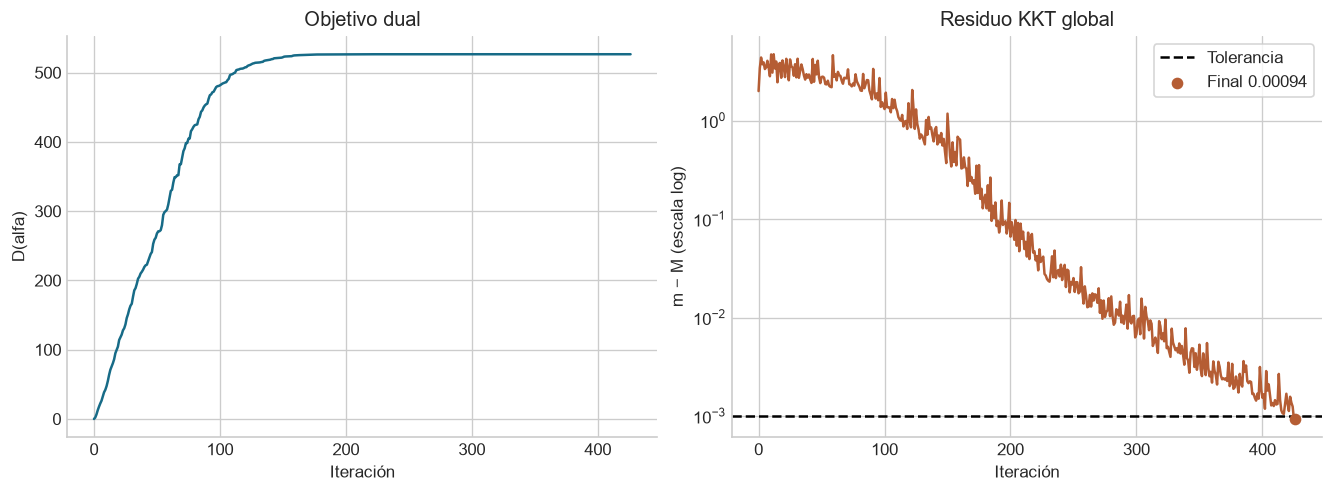

In [ ]:
# Estudiamos dos variedades y tomamos 400 filas de entrenamiento para poder inspeccionar el solver.
mascara = y_train.isin(['DERMASON', 'SIRA'])
X_smo, _, y_smo, _ = train_test_split(
    X_train.loc[mascara], y_train.loc[mascara], train_size=400,
    stratify=y_train.loc[mascara], random_state=SEMILLA
)
escalador_smo = StandardScaler().fit(X_smo)
xs = escalador_smo.transform(X_smo)
# El dual binario usa signos. Asignamos +1 a SIRA y −1 a DERMASON.
ys = np.where(y_smo.to_numpy() == 'SIRA', 1.0, -1.0)
# Ambos algoritmos reciben las mismas medidas, clases, C y gamma. LIBSVM usa una tolerancia más estricta.
propio = SMOBinary(C=8, kernel='rbf', gamma=1/64, tol=1e-3).fit(xs, ys)
referencia = SVC(C=8, kernel='rbf', gamma=1/64, tol=1e-6).fit(xs, ys)
resultado_smo = {
    'Filas del subconjunto': len(xs), 'Iteraciones': propio.n_iter_,
    'Convergió': propio.converged_, 'Residuo KKT global m-M': propio.kkt_gap_,
    'Tolerancia KKT': propio.tol, 'Residuo igualdad |alfa @ y|': propio.equality_residual_,
    'Mínimo alfa': float(propio.alpha_.min()),
    'Máximo alfa': float(propio.alpha_.max()),
    'Concordancia SMO / LIBSVM (mismos puntos)':
        float(np.mean(propio.predict(xs) == referencia.predict(xs))),
    'Soportes SMO': len(propio.support_), 'Soportes LIBSVM': len(referencia.support_),
}
display(pd.Series(resultado_smo, name='Resultado').to_frame())
assert propio.converged_, 'SMO no certificó convergencia: revisar antes de exponer.'
pd.Series(resultado_smo).to_csv(SALIDA / 'comprobacion_smo.csv')

# Izquierda: el objetivo que maximiza SMO. Derecha: comparar el residuo final con tol.
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
ejes[0].plot(propio.dual_history_, color='#176B87')
ejes[0].set(title='Objetivo dual', xlabel='Iteración', ylabel='D(alfa)')
# La escala logarítmica distingue valores de 0.1, 0.01 y 0.001.
ejes[1].semilogy(np.maximum(propio.gap_history_, 1e-12), color='#B55D34')
ejes[1].axhline(propio.tol, color='black', linestyle='--', label='Tolerancia')
ejes[1].set(title='Residuo KKT global', xlabel='Iteración', ylabel='m − M (escala log)')
ejes[1].scatter(len(propio.gap_history_)-1, max(propio.kkt_gap_, 1e-12),
                color='#B55D34', zorder=3, label=f'Final {propio.kkt_gap_:.2g}')
ejes[1].legend(loc='upper right', frameon=True)
fig.savefig(SALIDA / '04_convergencia_smo.png', dpi=170, bbox_inches='tight')
plt.show()

## Guardar modelo, tablas y gráficas
**Qué hace:** guarda el `Pipeline` completo para que el modelo conserve su escalador; exporta CSV, PNG y un manifiesto con parámetros, versiones y datos usados. El ZIP se crea al ejecutar esta celda.

En Colab, abre **Archivos**, busca `resultados_svm.zip` y elige **Descargar**. Para conservar también el notebook con resultados, usa **Archivo → Guardar** o **Archivo → Descargar → Descargar .ipynb**. No necesitas montar tu Drive ni conceder acceso a otros archivos.

In [ ]:
# Guardamos el pipeline completo para reutilizar la misma transformación al clasificar otros frijoles.
joblib.dump(modelo, SALIDA / 'modelo_svm_pipeline.joblib')
# El manifiesto reúne el origen de los datos, versiones y parámetros junto a las métricas.
manifiesto = {
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(),
    'fuente_repositorio': 'https://github.com/leonardopanduro-rgb/optimizacion-',
    'commit_fuente': COMMIT_FUENTE, 'sha256_dataset': hash_datos,
    'versiones': versiones, 'semilla': SEMILLA, 'test_size': FRACCION_PRUEBA,
    'n_train': len(X_train), 'n_test': len(X_test), 'columnas_X': list(X.columns),
    'cv': str(cv),
    'malla': malla,
    'seleccion': 'F1 macro medio en los pliegues de entrenamiento',
    'mejores_parametros': busqueda.best_params_,
    'f1_macro_cv_seleccionado': float(busqueda.best_score_),
    'metricas_test': metricas.to_dict(orient='records'),
    'segundos_busqueda_y_reajuste': segundos_busqueda,
    'smo': ({'convergio': bool(propio.converged_), 'kkt_global': float(propio.kkt_gap_)}
            if 'propio' in globals() else None),
    'alcance': 'Demo didáctica; dataset y partición previamente estudiados; no validación externa nueva',
}
(SALIDA / 'manifiesto.json').write_text(json.dumps(manifiesto, indent=2, ensure_ascii=False), encoding='utf-8')
shutil.make_archive('resultados_svm', 'zip', root_dir=SALIDA)
print('Listo: resultados_svm.zip y carpeta resultados_svm/')
print('Modelo guardado con escalador:', SALIDA / 'modelo_svm_pipeline.joblib')

Listo: resultados_svm.zip y carpeta resultados_svm/
Modelo guardado con escalador: resultados_svm\modelo_svm_pipeline.joblib


## Preguntas que pueden hacer durante la exposición

| Pregunta | Respuesta breve |
|---|---|
| ¿Por qué SVM? | Es un método supervisado apropiado para datos numéricos; permite estudiar margen, kernels y optimización convexa. Aquí evaluamos su desempeño, sin afirmar que supera a todos los métodos. |
| ¿Por qué escalar? | Porque RBF usa distancias y las variables tienen unidades y magnitudes diferentes. |
| ¿Qué pasa si C aumenta? | Se penalizan más las violaciones del margen; eso puede cambiar la frontera y favorecer sobreajuste. Se decide con validación. |
| ¿Y si gamma aumenta? | La influencia de cada punto se vuelve más local; puede generar fronteras más complejas. |
| ¿Por qué F1 macro? | Porque las siete clases tienen tamaños diferentes y queremos dar el mismo peso a cada clase. |
| ¿El modelo devuelve probabilidades? | Esta configuración devuelve etiquetas. Los valores de decisión no son probabilidades. |
| ¿SMO es otra SVM? | Es un algoritmo para resolver la optimización del entrenamiento de una SVM. |
| ¿Un buen acuerdo con LIBSVM demuestra generalización? | No. Comprueba consistencia de implementaciones; la generalización se evalúa con datos reservados. |
| ¿Por qué puede variar un resultado? | Por partición, búsqueda o versiones. Por eso registramos semilla, datos, parámetros y librerías. |
| ¿Es el mismo protocolo completo del informe? | Conserva limpieza, split y CV; usa una malla menor para enseñar el flujo. No reproduce todos los experimentos E1–E5. |

### Tres cambios que puedes ensayar en vivo

1. En **Visual 3**, cambia el valor de `C_MARGEN` entre 0.1, 1 y 10. Ejecuta esa celda y observa el ancho del margen y cuántos puntos quedan rodeados.
2. En la **sección 11**, prueba `FILA_DEMO = 48` con la configuración inicial. Lee primero la predicción y después la variedad real.
3. En la **sección 7**, elige `MODO_KERNEL = 'solo lineal'` y ejecuta las secciones 7 y 8. Compara el mejor F1 de validación con el de la malla inicial. Las secciones posteriores se actualizan al volver a ejecutarlas.

## Fuentes y atribución
- [Repositorio del equipo](https://github.com/leonardopanduro-rgb/optimizacion-).
- [UCI Dry Bean](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset), Koklu y Ozkan (2020), DOI [10.24432/C50S4B](https://doi.org/10.24432/C50S4B). Datos distribuidos por UCI con licencia CC BY 4.0.
- [SVM en scikit-learn](https://scikit-learn.org/stable/modules/svm.html) y [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- Código SMO procedente del repositorio del proyecto; atribución original `cruz-eng/ml-opti` y licencia MIT preservada abajo.

### Licencia del código reutilizado

```text
MIT License

Copyright (c) 2026 cruz-eng

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```